# 03 · Threats and frames

Handoff §3 Step 6 for **one site**, chosen by `DUNESIGHT_SITE` (boxes in `pipeline/sites.json`), built on notebook 02's measured motion. It writes the rest of the §4 data contract into `public/data/<site>/`: `targets.geojson`, the threat fields of `dunes.geojson` / `dunes_2000.geojson`, the timeline frames and `frames/manifest.json`, `summary.json` and `sources.json`; then it rebuilds `public/data/sites.json` and checks every file against the contract.

**What changed from the handoff, and why.** Step 6 was written for fast dunes with a polygon each. The measured result is different: at these UAE sites the dunes that move above the detection limit do so at roughly 0.5-2 m/yr (each site's numbers are printed below, from notebook 02, and interpreted in its site notes), and NASADEM outlines only the largest dunes. So:
- **Threat rests on the measured velocity field** (every detected 480 m window, every 120 m), not on the 21 polygons. The NASADEM polygons get their threat fields too, from their own motion.
- **"Reach" is defined for dune migration, not for blowing sand** (next section), and the reach years come from explicit speed and distance ranges.
- **Projected frames are faithful.** At these speeds the 2050 image differs from the 2025 image by a few 15 m pixels at most in moving places; the manifest says by how much, frame by frame. Nothing is exaggerated.

**Definition of "reach" (what a road engineer would sign).** Sand *reaches* a target in year Y when the edge of **migrating dune sand** (free sand inside a window whose dune-form migration is detected), carried along its measured heading at the measured speed, arrives at the edge of the target's footprint: the road formation (OSM centre line ± the class half width notebook 02 uses for carriageway and shoulders), the vegetated outline of a farm, or the outline of a built-up area.

It **excludes**: (1) wind-blown sand (saltation, drifting sand) crossing or settling on a road: that happens wherever a road borders loose sand, regardless of dune migration, and is reported separately as *borders free sand today*; (2) sand already lying on the target; (3) motion below the detection limit (no measured direction: never a hit); (4) dune deformation, merging, growth, levelling, stabilisation by vegetation or fences; (5) anything outside the box.

In [1]:
# WHAT THIS DOES: imports, picks the site from DUNESIGHT_SITE, sets folders, loads .env (secrets are never printed),
# reads notebook 02's outputs (QC summary, per-window velocity field, scenes, dunes) and sets the parameters of this notebook.
import json, os, sys, math, time, hashlib, datetime as dt
from pathlib import Path

PIPELINE = next(p for p in [Path.cwd(), Path.cwd() / "pipeline", Path.cwd().parent, Path.cwd().parent.parent]
                if (p / "dunesight").is_dir())
sys.path.insert(0, str(PIPELINE))

import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt
from scipy import ndimage
from dotenv import load_dotenv
from pyproj import Transformer
import shapely
from shapely.geometry import mapping, box as sbox, Point
from PIL import Image

from dunesight import config, site_index, wind, landsat, rasters, masks, tracking as tk, targets as tg, threat as th, frames as fr

for msg in ("Mean of empty slice", "All-NaN slice", "invalid value encountered", "divide by zero"):
    warnings.filterwarnings("ignore", message=f".*{msg}.*")

SITE = config.get_site()
SID = SITE["id"]
OUT = config.outputs_dir(SID); RAW = config.raw_dir(SID); PUB = config.public_dir(SID)
FRAMES = PUB / "frames"
SITE_CFG = config.PIPELINE / "site_config" / SID
load_dotenv(config.ROOT / ".env")
plt.rcParams.update({"figure.dpi": 60, "savefig.dpi": 90, "font.size": 9})

P = dict(
    road_segment_m=500,        # roads are split into equal pieces no longer than this
    farm_ndvi_margin=0.07,     # farm = median HLS NDVI over the last year >= box median + this (notebook 02 uses the same margin)
    farm_close_px=1,           # morphological closing (30 m pixels) so the tree rows of one plantation form one polygon
    farm_min_area_ha=0.5,      # smaller vegetated patches (single trees, gardens) are not farm targets
    farm_period=("2024-11-01", "2025-12-01"),   # HLS composite period: the last year before the latest Landsat scene, inclusive
    outline_unc_m={"road": 5.0, "building": 5.0, "farm": 15.0},   # target outline uncertainty: OSM ~5 m; HLS 30 m outline ~half a pixel
    window_half_m=240.0,       # a pixel inherits the motion of the nearest valid window whose 480 m footprint contains it
    horizon=2100,              # reach years beyond this are reported as null
    projection_end=2050,       # the projection window of the app; threat = reached (fast case) by this year
    frame_years=[2030, 2035, 2040, 2045, 2050],
    frame_res_m=15.0, jpeg_quality=85, stretch_pct=(0.5, 99.5), gamma=1.0,
    field_sigma_win=1.0, field_median_win=3,
)
P.update(SITE.get("notebook03", {}))

qc_path = OUT / "02_qc_summary.json"
vf_path = OUT / "02_velocity_field.csv"
for p_ in (qc_path, vf_path, PUB / "dunes.geojson", OUT / "02_dunes_table.csv", OUT / "02_scenes_downloaded.csv"):
    if not p_.exists():
        raise SystemExit(f"{p_.relative_to(config.ROOT)} is missing: run notebook 02 for {SID} first.")
QC2 = json.loads(qc_path.read_text())
VF = pd.read_csv(vf_path)
SC = pd.read_csv(OUT / "02_scenes_downloaded.csv")
CONF = json.loads((SITE_CFG / "scenes_confirmed.json").read_text())
SCONF = SC[SC.role == "confirmed"].sort_values("t").reset_index(drop=True)
LATEST = SCONF.iloc[-1]
T0 = float(LATEST.t)
P2 = QC2["parameters"]
print(f"site: {SID} ({SITE['name']}); box W,S,E,N = {config.bbox_list(SITE)}; EPSG:{SITE['epsg']}")
print("credentials present:", {k: bool(os.getenv(k)) for k in ("EE_PROJECT", "EARTHDATA_USERNAME", "EARTHDATA_PASSWORD")})
print(f"notebook 02 QC generated {QC2['generated_utc']}; {len(VF)} dune windows, {int(VF.valid.sum())} valid, {int(VF.detected.sum())} detected")
print(f"latest image: {LATEST.date} ({LATEST.scene_id}), t0 = {T0:.3f}")
print("parameters:", P)

site: sweihan (Sweihan dune field, NW of Al Ain); box W,S,E,N = [55.29, 24.42, 55.39, 24.51]; EPSG:32640
credentials present: {'EE_PROJECT': True, 'EARTHDATA_USERNAME': True, 'EARTHDATA_PASSWORD': True}
notebook 02 QC generated 2026-11-15T05:26:31Z; 2098 dune windows, 2045 valid, 1762 detected
latest image: 2025-11-08 (LC08_L1TP_160043_20251108_20251128_02_T1), t0 = 2025.853
parameters: {'road_segment_m': 500, 'farm_ndvi_margin': 0.07, 'farm_close_px': 1, 'farm_min_area_ha': 0.5, 'farm_period': ('2024-11-01', '2025-12-01'), 'outline_unc_m': {'road': 5.0, 'building': 5.0, 'farm': 15.0}, 'window_half_m': 240.0, 'horizon': 2100, 'projection_end': 2050, 'frame_years': [2030, 2035, 2040, 2045, 2050], 'frame_res_m': 15.0, 'jpeg_quality': 85, 'stretch_pct': (0.5, 99.5), 'gamma': 1.0, 'field_sigma_win': 1.0, 'field_median_win': 3}


In [2]:
# WHAT THIS DOES: rebuilds notebook 02's 15 m grid and its non-dune mask (vegetated ever, WorldCover, OSM, hand-drawn)
# from the cached layers, and loads the latest confirmed image.
g = QC2["velocity_field_table"]["grid"]
GRID = rasters.Grid(g["crs"], g["x0"], g["y0"], g["res"], g["width"], g["height"])
RES = GRID.res
assert GRID == rasters.site_grid(SITE["bbox"], SITE["epsg"], margin_m=P2["grid_margin_m"], res=RES, phase=7.5), "grid differs from notebook 02"
INBOX = rasters.box_mask(GRID, SITE["bbox"])
MASK_DIR = RAW / "masks"
ndv, _ = rasters.read(MASK_DIR / "landsat_ndvi_nov.tif")
wcv, _ = rasters.read(MASK_DIR / "worldcover_v200_2021.tif")
OSM02 = json.loads((MASK_DIR / "osm_features.json").read_text())
VEG, _ = masks.vegetated_mask(ndv[0], INBOX, ndvi_margin=P2["ndvi_margin"])
WCM = masks.worldcover_mask(wcv[0])
OSMM, _ = masks.osm_mask(OSM02, GRID)
MAN, man_info = masks.manual_mask(SITE_CFG / "manual_masks.geojson", GRID)
NONDUNE = VEG | WCM | OSMM | MAN
print(f"non-dune mask rebuilt: {100 * NONDUNE[INBOX].mean():.1f} % of the box (notebook 02: {QC2['masks']['inbox_pct_nondune_total']} %)")
assert abs(100 * NONDUNE[INBOX].mean() - QC2["masks"]["inbox_pct_nondune_total"]) < 0.15

def load_scene(scene_id):
    a, _ = rasters.read(RAW / "landsat_b8" / f"{scene_id}.tif")
    meta = json.loads((RAW / "landsat_b8" / f"{scene_id}.json").read_text())
    bad = masks.qa_mask(a[1].astype(np.uint16), dilate_px=1) | (a[0] == 0)
    rho = fr.toa_reflectance(a[0], meta)
    rho[bad] = np.nan
    return rho, meta, bad
IMG0, META0, _ = load_scene(LATEST.scene_id)
TO_PROJ = Transformer.from_crs("EPSG:4326", GRID.crs, always_xy=True).transform
TO_LL = Transformer.from_crs(GRID.crs, "EPSG:4326", always_xy=True).transform
b = SITE["bbox"]
BOX_LL = sbox(b["west"], b["south"], b["east"], b["north"])
BOX_P = rasters.reproject_geom(TO_PROJ, shapely.segmentize(BOX_LL, 0.001))
EXT = (GRID.x0, GRID.x0 + GRID.width * RES, GRID.y0 - GRID.height * RES, GRID.y0)
def gray(a):
    lo, hi = np.nanpercentile(a[INBOX], [1, 99]); return np.clip((np.nan_to_num(a, nan=np.nanmedian(a)) - lo) / (hi - lo), 0, 1)
BASE = gray(IMG0)
def frame_axes(ax, zoom=None, rgb_img=None):
    if rgb_img is None:
        ax.imshow(BASE, cmap="gray", extent=EXT)
    else:
        ax.imshow(rgb_img[0], extent=rgb_img[1])
    ax.plot(*BOX_P.exterior.xy, "c--", lw=0.8)
    if zoom is None:
        x0_, y0_, x1_, y1_ = BOX_P.bounds; ax.set_xlim(x0_ - 200, x1_ + 200); ax.set_ylim(y0_ - 200, y1_ + 200)
    else:
        ax.set_xlim(zoom[0], zoom[2]); ax.set_ylim(zoom[1], zoom[3])
    ax.set_xticks([]); ax.set_yticks([])

non-dune mask rebuilt: 63.4 % of the box (notebook 02: 63.4 %)


## 1 · Targets

**Roads and built-up areas: OpenStreetMap via the Overpass API.** One query for every `highway=*` way, `building=*` and `landuse=*` feature in the box plus a 0.005° margin; the query text, the retrieval time and the OSM database timestamp are recorded in `targets.geojson` and `sources.json`. Road classes kept as targets: motorway to tertiary and their links, unclassified, residential, living street, service, and roads under construction. Tracks, paths and footways are not treated as roads. Each road (same class and name/ref, or a chain of unnamed ways) is clipped to the box and split into equal segments of at most 500 m. Individual buildings are hardly mapped in OSM here, so built-up targets are OSM buildings plus OSM built-up land-use areas (residential, industrial, commercial, retail, construction); the count is reported as it is.

**Farms and plantations: NASA HLS NDVI.** OSM maps almost no farmland here. Farms are taken from the median NDVI of every Fmask-clear HLS L30 and S30 observation in the last year before the latest Landsat scene (30 m), thresholded relative to the bare-sand background (box median + 0.07, the rule notebook 02 uses), closed by one pixel so the tree rows of one plantation join into one polygon, holes filled, and kept if ≥ 0.5 ha. The result is cross-checked against notebook 02's vegetation mask (any-year November Landsat NDVI) and ESA WorldCover 2021 tree/cropland, and drawn over the image for a visual check.

In [3]:
# WHAT THIS DOES: queries Overpass (cached in pipeline/raw/<site>/targets/), builds road segments and built-up areas.
OSM_Q = tg.overpass_query(SITE["bbox"])
OSM_T, OSM_RETRIEVED = tg.fetch_overpass(OSM_Q, RAW / "targets" / "osm_targets.json")
OSM_BASE = OSM_T["osm3s"]["timestamp_osm_base"]
print(f"Overpass: {len(OSM_T['elements'])} elements; OSM database timestamp {OSM_BASE}; retrieved {OSM_RETRIEVED}")
ROADS = tg.roads(OSM_T, TO_PROJ, BOX_P, seg_len_m=P["road_segment_m"])
BUILT = tg.built_areas(OSM_T, TO_PROJ, BOX_P)
OSM_FARMS = tg.osm_farms(OSM_T, TO_PROJ, BOX_P)
hw_counts = pd.Series([e["tags"]["highway"] for e in OSM_T["elements"] if e.get("type") == "way" and "highway" in e.get("tags", {})]).value_counts()
print("OSM highway ways in the query area by class:", hw_counts.to_dict())
print(f"roads kept: {len(ROADS)} roads -> {sum(len(r['segments']) for r in ROADS)} segments, "
      f"{sum(s.length for r in ROADS for s in r['segments']) / 1000:.1f} km inside the box")
print(f"built-up targets: {len(BUILT)} ({pd.Series([x['kind'] for x in BUILT]).value_counts().to_dict() if BUILT else {}}); OSM farm polygons: {len(OSM_FARMS)}")

Overpass: 727 elements; OSM database timestamp 2026-11-15T04:10:14Z; retrieved 2026-11-15T04:11:20Z
OSM highway ways in the query area by class: {'service': 225, 'residential': 173, 'unclassified': 67, 'track': 48, 'tertiary': 38, 'primary': 14, 'trunk_link': 11, 'trunk': 8, 'construction': 8, 'primary_link': 5, 'bridleway': 2, 'footway': 2, 'proposed': 1}
roads kept: 513 roads -> 735 segments, 183.2 km inside the box
built-up targets: 79 ({'building=yes': 56, 'building=carport': 11, 'landuse=industrial': 7, 'landuse=residential': 5}); OSM farm polygons: 7


In [4]:
# WHAT THIS DOES: downloads (cached) the HLS L30 + S30 median-NDVI composite of the last year on HLS's 30 m grid, from Earth
# Engine NASA/HLS/HLSL30/v002 and NASA/HLS/HLSS30/v002 with the Fmask cloud/shadow bits masked, and a median true-colour image.
GH = rasters.site_grid(SITE["bbox"], SITE["epsg"], margin_m=P2["grid_margin_m"], res=30.0, phase=0.0)
INBOX_H = rasters.box_mask(GH, SITE["bbox"])
t_a, t_b = P["farm_period"]
farm_tif = RAW / "farms" / f"hls_ndvi_{t_a[:7]}_{t_b[:7]}.tif"
farm_meta_p = farm_tif.with_suffix(".meta.json")
if not (farm_tif.exists() and farm_meta_p.exists()):
    ee = landsat.ee_init(config.ROOT)
    BOXE = ee.Geometry.Rectangle(config.bbox_list(SITE), "EPSG:4326", False)
    def prep(coll, nir):
        c = (ee.ImageCollection(coll).filterBounds(BOXE).filterDate(t_a, t_b)
             .filter(ee.Filter.stringStartsWith("system:index", SITE["hls_tile"])))
        def f(im):
            clear = im.select("Fmask").bitwiseAnd(0b1110).eq(0)    # Fmask bits 1 cloud, 2 adjacent cloud/shadow, 3 cloud shadow
            return im.normalizedDifference([nir, "B4"]).rename("ndvi").addBands(im.select(["B4", "B3", "B2"])).updateMask(clear)
        return c, c.map(f)
    cl0, cl = prep("NASA/HLS/HLSL30/v002", "B5")
    cs0, cs = prep("NASA/HLS/HLSS30/v002", "B8A")
    c_ = cl.merge(cs)
    comp = ee.Image.cat([c_.select("ndvi").reduce(ee.Reducer.percentile([25, 50, 90])), c_.select(["B4", "B3", "B2"]).median(),
                         c_.select("ndvi").count().rename("n_clear")]).toFloat()
    rasters.ee_download(comp, GH, farm_tif, comp.bandNames().getInfo())
    ids = {"HLSL30": cl0.aggregate_array("system:index").getInfo(), "HLSS30": cs0.aggregate_array("system:index").getInfo()}
    farm_meta_p.write_text(json.dumps({"period": [t_a, t_b], "tile": SITE["hls_tile"], "granules": ids,
                                       "bands": comp.bandNames().getInfo()}, indent=1))
FM = json.loads(farm_meta_p.read_text())
HA, _ = rasters.read(farm_tif)
ND50, NCLEAR = HA[1], HA[6]
HLS_DATES = sorted({s.split("_")[1][:8] for v in FM["granules"].values() for s in v})
print(f"HLS composite {t_a} to {t_b} (end exclusive): {len(FM['granules']['HLSL30'])} L30 + {len(FM['granules']['HLSS30'])} S30 granules on tile {FM['tile']}, "
      f"{HLS_DATES[0]}-{HLS_DATES[-1]}; clear observations per pixel in the box: {int(np.min(NCLEAR[INBOX_H]))}-{int(np.max(NCLEAR[INBOX_H]))}")

HLS composite 2024-11-01 to 2025-12-01 (end exclusive): 49 L30 + 90 S30 granules on tile T40RCN, 20241103-20251128; clear observations per pixel in the box: 85-127


farms/plantations: 59 polygons, 1095.4 ha; NDVI threshold 0.176 (box median 0.106)
cross-check: {'farm_area_ha': 1095.4, 'share_in_nb02_vegetated_mask_pct': 65.2, 'share_worldcover_tree_or_cropland_pct': 22.4, 'nb02_vegetated_in_box_ha': 1045.2, 'nb02_vegetated_in_box_inside_farms_pct': 68.3, 'ndvi_threshold': 0.176, 'box_median_ndvi': 0.106}


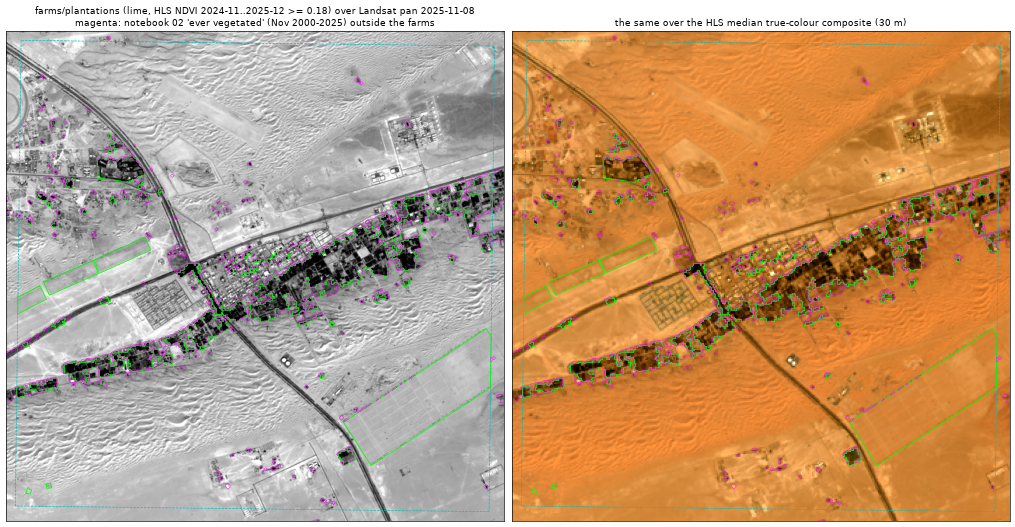

In [5]:
# WHAT THIS DOES: builds the farm/plantation polygons, cross-checks them with notebook 02's vegetation mask and WorldCover,
# and draws them over the latest image and the HLS true-colour composite for a visual check.
FARM_M, FARM_THR = tg.farm_mask(ND50, INBOX_H, margin=P["farm_ndvi_margin"], close_px=P["farm_close_px"], min_area_ha=P["farm_min_area_ha"])
farm_polys = [p.intersection(BOX_P) for p in tg.polygons_from_mask(FARM_M, GH)]
farm_polys = [p for p in farm_polys if not p.is_empty and p.area >= P["farm_min_area_ha"] * 1e4]
for of in OSM_FARMS:   # OSM-mapped farmland, merged with an NDVI farm where they overlap
    hit = [k for k, p in enumerate(farm_polys) if p.intersects(of["geometry"])]
    if hit:
        farm_polys[hit[0]] = shapely.union(farm_polys[hit[0]], of["geometry"])
    else:
        farm_polys.append(of["geometry"])
FARM_SRC = ["HLS NDVI" if not any(p.intersects(of["geometry"]) for of in OSM_FARMS) else "HLS NDVI + OSM landuse" for p in farm_polys]
# cross-check on the 15 m grid
from rasterio.features import rasterize
def rast(geoms, grid=GRID, all_touched=False):
    geoms = [g_ for g_ in geoms if g_ is not None and not g_.is_empty]
    if not geoms:
        return np.zeros((grid.height, grid.width), bool)
    return rasterize([(g_, 1) for g_ in geoms], out_shape=(grid.height, grid.width), transform=grid.affine(), all_touched=all_touched, dtype="uint8").astype(bool)
FARM15 = rast(farm_polys)
wc_tree_crop = np.isin(wcv[0], [10, 40])
xcheck = {"farm_area_ha": round(float(FARM15.sum() * RES ** 2 / 1e4), 1),
          "share_in_nb02_vegetated_mask_pct": round(100 * float(VEG[FARM15].mean()), 1) if FARM15.any() else None,
          "share_worldcover_tree_or_cropland_pct": round(100 * float(wc_tree_crop[FARM15].mean()), 1) if FARM15.any() else None,
          "nb02_vegetated_in_box_ha": round(float((VEG & INBOX).sum() * RES ** 2 / 1e4), 1),
          "nb02_vegetated_in_box_inside_farms_pct": round(100 * float(FARM15[VEG & INBOX].mean()), 1) if (VEG & INBOX).any() else None,
          "ndvi_threshold": round(FARM_THR, 3), "box_median_ndvi": round(float(np.nanmedian(ND50[INBOX_H])), 3)}
print(f"farms/plantations: {len(farm_polys)} polygons, {xcheck['farm_area_ha']} ha; NDVI threshold {FARM_THR:.3f} (box median {xcheck['box_median_ndvi']})")
print("cross-check:", xcheck)
rgb = np.dstack([HA[3], HA[4], HA[5]]); lo_, hi_ = np.nanpercentile(rgb[INBOX_H], [1, 99.5]); rgb = np.clip((rgb - lo_) / (hi_ - lo_), 0, 1)
EXTH = (GH.x0, GH.x0 + GH.width * 30, GH.y0 - GH.height * 30, GH.y0)
fig, axes = plt.subplots(1, 2, figsize=(17, 8.6))
frame_axes(axes[0]); frame_axes(axes[1], rgb_img=(rgb, EXTH))
for a in axes:
    for p_ in farm_polys:
        for g_ in getattr(p_, "geoms", [p_]):
            a.plot(*g_.exterior.xy, color="lime", lw=0.9)
    a.contour(np.flipud(VEG & ~FARM15), [0.5], colors="magenta", linewidths=0.5, extent=EXT, origin="lower")
axes[0].set_title(f"farms/plantations (lime, HLS NDVI {t_a[:7]}..{t_b[:7]} >= {FARM_THR:.2f}) over Landsat pan {LATEST.date}\nmagenta: notebook 02 'ever vegetated' (Nov 2000-2025) outside the farms")
axes[1].set_title("the same over the HLS median true-colour composite (30 m)")
plt.tight_layout(); plt.savefig(OUT / "03_farms_check.png"); plt.show()

In [6]:
# WHAT THIS DOES: assembles the target list with stable ids and names, and each target's footprint (the polygon a
# migrating sand front has to enter).
TG = []
ri = 0
for r in ROADS:
    ri += 1
    nseg = len(r["segments"])
    base = r["name"] or f"Unnamed {r['cls'].replace('_', ' ')} road (OSM way {r['ways'][0]})"
    if r["cls"] == "construction":
        base += " (under construction)"
    for k, s in enumerate(r["segments"], 1):
        TG.append(dict(id=f"R{ri:03d}-{k:02d}", name=f"{base}, segment {k} of {nseg}" if nseg > 1 else base, type="road",
                       cls=r["cls"], osm_ways=r["ways"], line=s, footprint=s.buffer(r["half_width_m"], cap_style="flat"),
                       half_width_m=r["half_width_m"], size=round(s.length, 1), source="OpenStreetMap (Overpass)"))
for k, (p_, src) in enumerate(sorted(zip(farm_polys, FARM_SRC), key=lambda z: -z[0].centroid.y), 1):
    TG.append(dict(id=f"F{k:03d}", name=f"Farm/plantation F{k:03d} ({p_.area / 1e4:.1f} ha, vegetated {t_a[:4]}-{t_b[:4]})", type="farm", cls="farm",
                   osm_ways=[], line=None, footprint=p_, half_width_m=None, size=round(p_.area / 1e4, 2), source=src))
for k, x in enumerate(sorted(BUILT, key=lambda z: -z["geometry"].centroid.y), 1):
    nm = x["name"] or ("Building" if x["kind"].startswith("building") else f"Built-up area ({x['kind']})")
    TG.append(dict(id=f"B{k:03d}", name=f"{nm} [{x['osm']}]", type="building", cls=x["kind"], osm_ways=[x["osm"]], line=None,
                   footprint=x["geometry"], half_width_m=None, size=round(x["geometry"].area / 1e4, 2), source="OpenStreetMap (Overpass)"))
assert len({t["id"] for t in TG}) == len(TG)
print(pd.Series([t["type"] for t in TG]).value_counts().to_dict(), "targets")

{'road': 735, 'building': 79, 'farm': 59} targets


## 2 · Threat: where migrating sand reaches a target, and when

**Sources.** Free dune sand is every 15 m pixel inside the box that is outside notebook 02's non-dune mask and outside every target footprint. Each such pixel inherits the motion of the nearest valid dune window whose 480 m footprint contains it. Only windows with **detected** motion make sources: a window below the detection limit has no measured direction, so it can never produce a hit.

**Rays.** From every source, a ray along the measured heading, as long as the fast case travels by 2100. The first target footprint it enters is the target that sand reaches; the distance is measured to the entry point.

**Distance and its uncertainty.** The sand edge lies somewhere inside the source pixel, so the nominal gap is d = (distance from the pixel centre) − 7.5 m, floored at 0, with an uncertainty of ±(7.5 m + the target's outline uncertainty: 5 m for OSM roads and buildings, 15 m for 30 m HLS farm outlines).

**Speeds and years.** For each window: median = its measured speed v; fast = v + σ; slow = v − σ, with σ the calibrated per-component 1-σ uncertainty from notebook 02 (so fast and slow are the 84th and 16th percentiles of the speed; slow is always > 0 because detection requires v > 2.45 σ). With t0 the date of the latest image:
- `hit_year_min` = ⌊t0 + d_lo / fast⌋ (shortest plausible gap, fast case),
- `hit_year_med` = t0 + d / v rounded (additive field),
- `hit_year_max` = ⌈t0 + d_hi / slow⌉ (longest plausible gap, slow case),

each the earliest over all sand reaching that target. `null` when even the fast case does not arrive by 2100; `hit_year_max` is also `null` (with the uncapped value in `hit_year_max_uncapped`) when the slow case arrives after 2100. Rays are also cast at the heading ± its 1-σ direction uncertainty (σ/v radians); a target hit only by those is marked *possible within the direction uncertainty* but gets no reach year.

**Status of each target** (`threat_status`): `sand_at_edge_now` (migrating sand already within the edge uncertainty and moving toward it), `reached_by_2050`, `reached_2051_2100`, `possible_within_direction_uncertainty`, `not_reached_by_2100`. Separately, `borders_free_sand` says whether any free sand lies within 30 m of the footprint today, whatever it is doing: that is where blowing sand reaches a road now.

In [7]:
# WHAT THIS DOES: builds the source pixels with their window motion, casts the rays (central heading and the +-1 sigma
# direction fan) and aggregates the reach years per target.
FOOT = rast([t["footprint"] for t in TG])
WIDX = th.assign_windows(GRID, VF.x_m.values, VF.y_m.values, VF.valid.values, max_offset_m=P["window_half_m"])
FREE = INBOX & ~NONDUNE & ~FOOT
DETW = np.where(WIDX >= 0, VF.detected.values[np.maximum(WIDX, 0)], False)
SRC = FREE & DETW
sr, sc = np.nonzero(SRC)
sw = WIDX[sr, sc]
sx, sy = GRID.xy(sr, sc)
vE_s, vN_s, sg_s = VF.east_myr.values[sw], VF.north_myr.values[sw], VF.sigma_myr.values[sw]
TGEOM = [(t["footprint"], P["outline_unc_m"][t["type"]]) for t in TG]
print(f"free dune sand in the box: {100 * FREE[INBOX].mean():.1f} % of the box; of it covered by a valid window {100 * (FREE & (WIDX >= 0))[INBOX].sum() / FREE[INBOX].sum():.1f} %, "
      f"with detected motion (sources) {100 * SRC[INBOX].sum() / FREE[INBOX].sum():.1f} % = {SRC.sum()} pixels")
t_ = time.time()
RC = th.cast(sx, sy, vE_s, vN_s, sg_s, TGEOM, T0, horizon=P["horizon"], res=RES)
RF = [th.cast(sx, sy, vE_s, vN_s, sg_s, TGEOM, T0, horizon=P["horizon"], res=RES, fan=f_) for f_ in (-1.0, 1.0)]
print(f"rays cast in {time.time() - t_:.1f} s; sources reaching a target by {P['horizon']}: {int((RC['target'] >= 0).sum())} (central heading), "
      f"{int(((RF[0]['target'] >= 0) | (RF[1]['target'] >= 0)).sum())} (within the direction fan)")
AGG = th.per_target(RC, len(TG))
if not (RC["target"] >= 0).any():
    print(f"no detected motion toward targets: no target is reached by {P['horizon']} along a measured heading "
          f"({SRC.sum()} source pixels with detected motion, {int(VF.detected.sum())} detected windows)")
FAN = [set(np.unique(r_["target"][r_["target"] >= 0]).tolist()) for r_ in RF]
FAN_HIT = FAN[0] | FAN[1]
# blowing-sand exposure: free sand (any motion) within 30 m of the footprint
LAB = np.zeros(FOOT.shape, np.int32)
for k, t in enumerate(TG):          # later targets overwrite earlier ones where footprints overlap (roads first, then farms, built-up)
    m_ = rast([t["footprint"]], all_touched=True)
    LAB[m_] = k + 1
DIST_FREE = ndimage.distance_transform_edt(~FREE) * RES
gap_free = ndimage.minimum(DIST_FREE, LAB, index=np.arange(1, len(TG) + 1))
def status(k):
    a = AGG[k]
    if a is None:
        return "possible_within_direction_uncertainty" if k in FAN_HIT else "not_reached_by_2100"
    if np.nanmin(RC["d_lo"][RC["target"] == k]) == 0:
        return "sand_at_edge_now"
    return "reached_by_2050" if math.floor(a["year_min"]) <= P["projection_end"] else "reached_2051_2100"   # same integer year as hit_year_min
for k, t in enumerate(TG):
    a = AGG[k]
    t["status"] = status(k)
    t["borders_free_sand"] = bool(np.isfinite(gap_free[k]) and gap_free[k] <= 30.0)
    t["free_sand_gap_m"] = None if not np.isfinite(gap_free[k]) else round(float(max(0.0, gap_free[k] - RES / 2)), 1)
    if a is None:
        t.update(hit_year_min=None, hit_year_max=None, hit_year_med=None, hit_year_max_uncapped=None, gap_m=None, approach=None)
        continue
    y_max = int(math.ceil(a["year_max"]))
    j = a["src_first"]
    t.update(hit_year_min=int(math.floor(a["year_min"])), hit_year_med=int(round(a["year_med"])),
             hit_year_max=y_max if y_max <= P["horizon"] else None, hit_year_max_uncapped=y_max,
             gap_m=round(a["gap_m"], 1), n_sources=a["n_sources"],
             approach={"speed_myr": round(float(RC["speed"][j]), 2), "fast_myr": round(float(RC["fast"][j]), 2), "slow_myr": round(float(RC["slow"][j]), 2),
                       "heading_deg": round(float(tk.heading_deg(vE_s[j], vN_s[j])), 1), "gap_m": round(float(RC["d_nom"][j]), 1),
                       "gap_lo_m": round(float(RC["d_lo"][j]), 1), "gap_hi_m": round(float(RC["d_hi"][j]), 1),
                       "window_lonlat": [round(float(VF.lon[sw[j]]), 5), round(float(VF.lat[sw[j]]), 5)],
                       "hit_point_lonlat": [round(float(c_), 6) for c_ in TO_LL(RC["hit_x"][j], RC["hit_y"][j])],
                       "sand_edge_lonlat": [round(float(c_), 6) for c_ in TO_LL(sx[j], sy[j])]})
    t["hit_xy"] = (float(RC["hit_x"][j]), float(RC["hit_y"][j]))
TT = pd.DataFrame([{k_: t[k_] for k_ in ("id", "name", "type", "status", "hit_year_min", "hit_year_med", "hit_year_max", "hit_year_max_uncapped", "gap_m",
                                          "borders_free_sand", "free_sand_gap_m")} | (t["approach"] or {}) for t in TG])
print("\ntargets by status and type:")
print(pd.crosstab(TT.status, TT.type, margins=True).to_string())
print("\nborders free sand today (within 30 m), by type:", TT[TT.borders_free_sand].type.value_counts().to_dict())
fl = TT[TT.hit_year_min.notna()].sort_values(["hit_year_min", "hit_year_med"])
print(f"\nreached by {P['horizon']} (fast case): {len(fl)} targets; earliest:")
print(fl.head(25)[["id", "name", "status", "hit_year_min", "hit_year_med", "hit_year_max_uncapped", "gap_m", "speed_myr", "heading_deg"]].to_string(index=False))
TT.to_csv(OUT / "03_targets_table.csv", index=False)

free dune sand in the box: 36.6 % of the box; of it covered by a valid window 96.3 %, with detected motion (sources) 79.5 % = 130776 pixels


rays cast in 0.9 s; sources reaching a target by 2100: 1644 (central heading), 1938 (within the direction fan)



targets by status and type:
type                                   building  farm  road  All
status                                                          
not_reached_by_2100                          76    48   724  848
possible_within_direction_uncertainty         0     1     0    1
reached_by_2050                               3     1     2    6
sand_at_edge_now                              0     9     9   18
All                                          79    59   735  873

borders free sand today (within 30 m), by type: {'road': 273, 'farm': 40, 'building': 8}

reached by 2100 (fast case): 24 targets; earliest:
     id                                                                                name           status  hit_year_min  hit_year_med  hit_year_max_uncapped  gap_m  speed_myr  heading_deg
   F038                                  Farm/plantation F038 (3.9 ha, vegetated 2024-2025) sand_at_edge_now        2025.0        2026.0                 2065.0    0.0       0.67      

### Dunes (the NASADEM-resolved dunes)

The same rays, cast from every pixel of each dune's 2025 outline along **that dune's** measured motion (vector median of the windows around it, notebook 02), with its speed ± its uncertainty. A dune below the detection limit has no measured heading: `threat = false`, reach years `null`, and `nearest_target` / `distance_to_target_m` give the closest target in a straight line, for context only (`threat_basis` says which). `threat = true` when the fast case reaches a target by the end of the projection window (2050), as the handoff defines it. Caveat: the outlines are the upper half of each dune body (NASADEM, February 2000, shifted to 2025), so the dune toe lies further out than the outline and distances measured from the outline are upper bounds.

In [8]:
# WHAT THIS DOES: computes the threat fields of the NASADEM dunes and writes them into dunes.geojson and dunes_2000.geojson,
# leaving every other field unchanged.
DJ = json.loads((PUB / "dunes.geojson").read_text())
D0 = json.loads((PUB / "dunes_2000.geojson").read_text())
DT2 = pd.read_csv(OUT / "02_dunes_table.csv").set_index("id")
from shapely.geometry import shape
foot_all = [t["footprint"] for t in TG]
tree_all = shapely.STRtree(foot_all)
dune_rows = []
for f in DJ["features"]:
    pr = f["properties"]
    gp = rasters.reproject_geom(TO_PROJ, shape(f["geometry"]))
    upd = {}
    if not pr["below_detection_limit"] and pr["heading_deg"] is not None:
        m_ = rast([gp]) & ~FOOT
        rr_, cc_ = np.nonzero(m_)
        xx, yy = GRID.xy(rr_, cc_)
        vE_d, vN_d = float(DT2.loc[pr["id"], "vE_myr"]), float(DT2.loc[pr["id"], "vN_myr"])
        sg_d = float(pr["uncertainty_myr"])
        n_ = rr_.size
        r_ = th.cast(xx, yy, np.full(n_, vE_d), np.full(n_, vN_d), np.full(n_, sg_d), TGEOM, T0, horizon=P["horizon"], res=RES)
        a_ = th.per_target(r_, len(TG))
        hits = [(k, a) for k, a in enumerate(a_) if a is not None]
    else:
        hits = []
    if hits:
        k, a = min(hits, key=lambda z: z[1]["year_min"])
        ymin, ymax = int(math.floor(a["year_min"])), int(math.ceil(a["year_max"]))
        upd = dict(threat=bool(ymin <= P["projection_end"]), nearest_target=TG[k]["name"], distance_to_target_m=round(a["gap_m"], 1),
                   reach_year_min=ymin, reach_year_max=ymax if ymax <= P["horizon"] else None)
        basis = f"along the measured heading; target {TG[k]['id']}"
    else:
        near = tree_all.nearest(gp)
        dd = float(gp.distance(foot_all[near]))
        upd = dict(threat=False, nearest_target=TG[near]["name"], distance_to_target_m=round(dd, 1), reach_year_min=None, reach_year_max=None)
        basis = ("straight-line distance only: motion below the detection limit (no measured heading)" if pr["below_detection_limit"]
                 else f"straight-line distance only: nothing lies along the measured heading within the fast-case reach by {P['horizon']}")
        basis += f"; target {TG[near]['id']}"
    pr.update(upd)
    pr["threat_basis"] = basis
    pr["threat_status"] = "computed (notebook 03)"
    pr["threat_definition"] = (f"threat = the fast case (speed + 1 sigma) of this dune's measured motion carries its outline onto a target footprint by "
                               f"{P['projection_end']}; reach years: fast case over the shortest plausible gap (min), slow case (speed - 1 sigma) over the longest (max)")
    dune_rows.append({"id": pr["id"], "class": pr["class"], "below_detection_limit": pr["below_detection_limit"], **upd, "basis": basis})
assert [f["properties"]["id"] for f in DJ["features"]] == [f["properties"]["id"] for f in D0["features"]]
for f0, f in zip(D0["features"], DJ["features"]):   # dunes_2000: same ids; carry the threat fields so both files agree
    for k_ in ("threat", "nearest_target", "distance_to_target_m", "reach_year_min", "reach_year_max"):
        f0["properties"][k_] = f["properties"][k_]
DUN = pd.DataFrame(dune_rows)
print(DUN.to_string(index=False))
NOTE03 = {"dj": " Threat fields computed by pipeline/03_threats_and_frames.ipynb (see threat_definition).",
          "d0": " Threat fields copied from dunes.geojson (notebook 03)."}
for obj, key in ((DJ, "dj"), (D0, "d0")):   # idempotent: re-running notebook 03 on its own output leaves the note unchanged
    n_ = obj["note"].replace("Threat fields are not computed yet (notebook 03). ", "")
    for v_ in NOTE03.values():
        n_ = n_.replace(v_, "")
    obj["note"] = n_ + NOTE03[key]
(PUB / "dunes.geojson").write_text(json.dumps(DJ, separators=(",", ":")) + "\n")
(PUB / "dunes_2000.geojson").write_text(json.dumps(D0, separators=(",", ":")) + "\n")
print(f"dunes with threat = true: {int(DUN.threat.sum())} of {len(DUN)}")

  id  class  below_detection_limit  threat                                                nearest_target  distance_to_target_m reach_year_min reach_year_max                                                                                                                   basis
D001 stable                   True   False            Built-up area (landuse=industrial) [way/360800376]                 172.6           None           None                        straight-line distance only: motion below the detection limit (no measured heading); target B069
D002   slow                  False   False                             E16 At Taf Road, segment 29 of 42                 561.3           None           None straight-line distance only: nothing lies along the measured heading within the fast-case reach by 2100; target R003-29
D003   slow                  False   False            Built-up area (landuse=industrial) [way/448047856]                 858.2           None           None    straight-

### Looking at it

The overview shows every target coloured by status, the detected motion, and the source sand. The zooms show the earliest-reached targets and, for comparison, unflagged targets that border free sand: a flagged target should have bright dune sand at its edge with arrows pointing at it; an unflagged one should have sand that is still, moving along it or away, or far away.

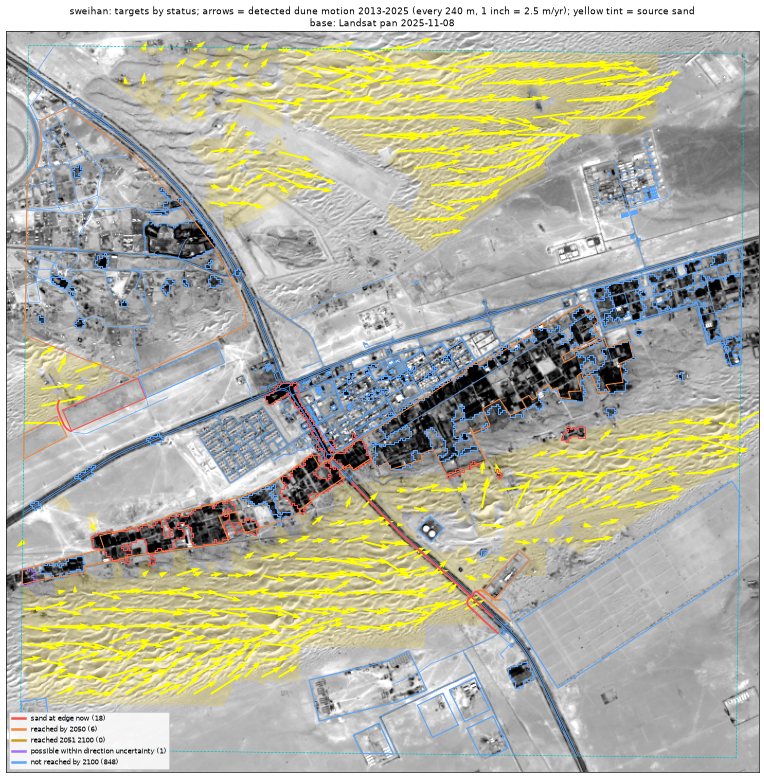

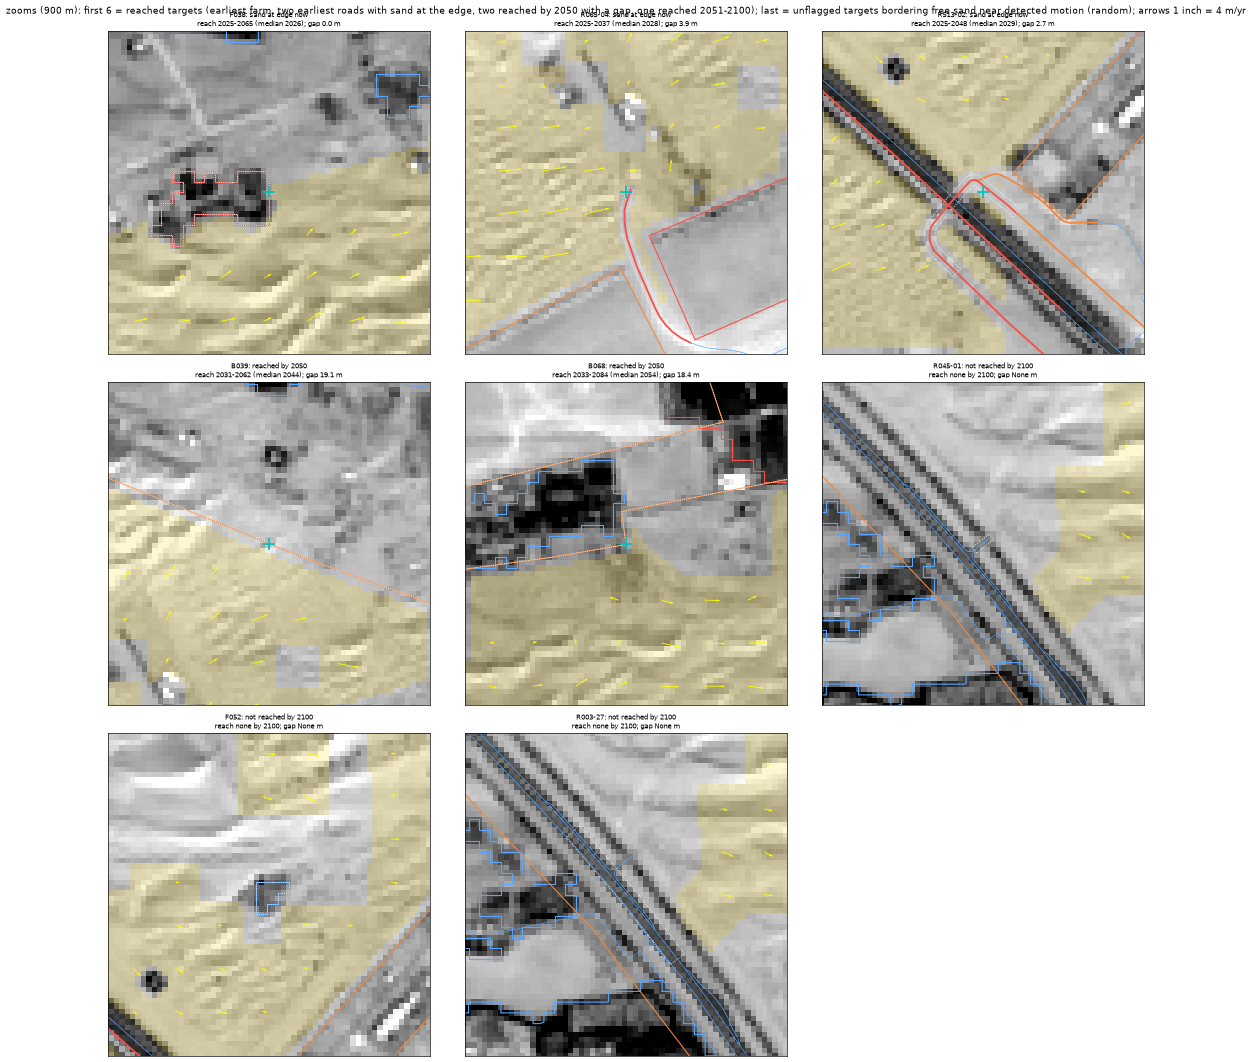

zoomed: ['F038', 'R065-04', 'R513-02', 'B039', 'B068', np.str_('R045-01'), np.str_('F052'), np.str_('R003-27')]


In [9]:
# WHAT THIS DOES: draws the by-eye validation figures (overview and zooms) and saves them to pipeline/outputs/<site>/.
COL = {"sand_at_edge_now": "#f85149", "reached_by_2050": "#f0883e", "reached_2051_2100": "#d29922",
       "possible_within_direction_uncertainty": "#a371f7", "not_reached_by_2100": "#58a6ff"}
det = VF[VF.detected]
def draw_targets(ax, sel=None, lw=1.0):
    for t in TG if sel is None else sel:
        c_ = COL[t["status"]]
        if t["type"] == "road":
            ax.plot(*t["line"].xy, color=c_, lw=lw * (2.2 if t["status"] != "not_reached_by_2100" else 0.8))
        else:
            for g_ in getattr(t["footprint"], "geoms", [t["footprint"]]):
                ax.plot(*g_.exterior.xy, color=c_, lw=lw * 1.3)
def draw_motion(ax, thin=1, scale=1.5):
    d_ = det[(det.win_row % (8 * thin) == det.win_row.min() % (8 * thin)) & (det.win_col % (8 * thin) == det.win_col.min() % (8 * thin))] if thin > 1 else det
    return ax.quiver(d_.x_m, d_.y_m, d_.east_myr, d_.north_myr, color="yellow", scale=scale, scale_units="inches", width=0.0025)
fig, ax = plt.subplots(figsize=(13, 13))
frame_axes(ax)
ov = np.zeros((*SRC.shape, 4)); ov[SRC] = (1, 0.85, 0, 0.18); ax.imshow(ov, extent=EXT)
draw_targets(ax); draw_motion(ax, thin=2, scale=2.5)
for s_, c_ in COL.items():
    ax.plot([], [], color=c_, lw=3, label=f"{s_.replace('_', ' ')} ({int((TT.status == s_).sum())})")
ax.legend(loc="lower left", fontsize=8, framealpha=0.85)
ax.set_title(f"{SID}: targets by status; arrows = detected dune motion 2013-2025 (every 240 m, 1 inch = 2.5 m/yr); yellow tint = source sand\nbase: Landsat pan {LATEST.date}")
plt.tight_layout(); plt.savefig(OUT / "03_threat_overview.png"); plt.show()

rng = np.random.default_rng(20261114)
def pick(df, n):
    return [x for x in df.id.head(n)]
flag_ids = (pick(fl[(fl.type == "farm")], 1) + pick(fl[(fl.type == "road") & (fl.status == "sand_at_edge_now")], 2)
            + pick(fl[fl.status == "reached_by_2050"], 2) + pick(fl[fl.status == "reached_2051_2100"], 1))
unfl = TT[(TT.status == "not_reached_by_2100") & TT.borders_free_sand]
near_det = [t_["id"] for t_ in TG if len(det) and t_["id"] in set(unfl.id) and np.hypot(det.x_m - t_["footprint"].centroid.x, det.y_m - t_["footprint"].centroid.y).min() < 300]
unfl_ids = list(rng.choice(near_det, size=min(3, len(near_det)), replace=False)) if near_det else []
show = flag_ids + unfl_ids
if show:
    ncol = 3; nrow = int(math.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 6 * nrow))
    for a, tid in zip(np.atleast_1d(axes).ravel(), show):
        t = next(x for x in TG if x["id"] == tid)
        cx, cy = t["hit_xy"] if t.get("hit_xy") else (t["footprint"].centroid.x, t["footprint"].centroid.y)   # centre on where sand enters
        z = (cx - 450, cy - 450, cx + 450, cy + 450)
        frame_axes(a, z)
        a.imshow(ov, extent=EXT)
        draw_targets(a, [x for x in TG if x["footprint"].distance(Point(cx, cy)) < 700])
        draw_motion(a, thin=1, scale=4)
        a.plot(*t["footprint"].exterior.xy if t["footprint"].geom_type == "Polygon" else t["footprint"].convex_hull.exterior.xy, "w:", lw=1)
        yrs = f"{t['hit_year_min']}-{t['hit_year_max'] or '>' + str(P['horizon'])} (median {t['hit_year_med']})" if t["hit_year_min"] else "none by 2100"
        if t.get("hit_xy"):
            a.plot(*t["hit_xy"], "c+", ms=14, mew=2)
        a.set_title(f"{tid}: {t['status'].replace('_', ' ')}\nreach {yrs}; gap {t['gap_m']} m", fontsize=8)
    for a in np.atleast_1d(axes).ravel()[len(show):]:
        a.axis("off")
    plt.suptitle("zooms (900 m): first 6 = reached targets (earliest farm, two earliest roads with sand at the edge, two reached by 2050 with a gap, one reached 2051-2100); last = unflagged targets bordering free sand near detected motion (random); arrows 1 inch = 4 m/yr")
    plt.tight_layout(); plt.savefig(OUT / "03_threat_zooms.png"); plt.show()
print("zoomed:", show if show else "none (no target reached and no unflagged target near detected motion)")

## 3 · Frames for the timeline

**Observed.** One frame per confirmed November scene (notebook 02's list), from the cached Landsat B8 rasters: top-of-atmosphere reflectance corrected for sun elevation, and **one linear stretch per instrument, identical for every year of that instrument** (0.5-99.5 percentiles of that instrument's scenes pooled inside the box). One stretch per instrument rather than one overall because the ETM+ pan band (0.52-0.90 µm) reaches into the near-infrared, where sand is brighter, while OLI/OLI-2 pan is 0.50-0.68 µm: a single stretch clipped the Landsat 7 frames and used only half the grey range for Landsat 8/9. Landsat 8 and 9 share one stretch (same band). Brightness differences between an ETM+ and an OLI frame are therefore partly instrumental; within each instrument they are real. QA-masked pixels (fill, cloud, dilated cloud, cirrus, shadow) set to no-data, and resampled (bilinear) to a lon/lat grid whose edges are exactly the box, so the stated WGS84 bounds are exact. Saved as JPEG (no transparency needed; no-data would be black and is counted per frame in the manifest).

**Projected.** The latest observed image advected along the smoothed measured motion (semi-Lagrangian: every output pixel takes the value found upstream along the motion), to November of 2030, 2035, 2040, 2045 and 2050. The motion field is the per-window velocity of **detected** windows only (zero where motion is below the detection limit, invalid, non-dune or masked), median-filtered (3 × 3 windows) and Gaussian-smoothed (σ = one 120 m window step), interpolated to the 15 m pixels and multiplied by a feathered mask that is 1 on free sand under a detected window and 0 elsewhere. **Median case**: the measured velocity. **Fast case**: the same heading at speed + σ (the 84th percentile of the speed, from the calibrated per-window uncertainty). Saved as PNG with an alpha channel (transparent = no-data). The manifest carries, per frame, how far the image was moved: the share of the box that moves at all, and the median, 90th percentile and maximum displacement in metres and pixels.

First, the warp is tested on a synthetic case with a known uniform velocity.

In [10]:
# WHAT THIS DOES: synthetic test of the advection: a Gaussian blob moved by a known uniform velocity must land the right
# distance in the right direction, both on the UTM grid and after resampling to the WGS84 frame grid.
rows = []
yy_, xx_ = np.mgrid[0:GRID.height, 0:GRID.width]
cr, cc0 = GRID.rowcol(*TO_PROJ((b["west"] + b["east"]) / 2, (b["south"] + b["north"]) / 2))
blob = np.exp(-((yy_ - cr) ** 2 + (xx_ - cc0) ** 2) / (2 * 4.0 ** 2))
for vE_t, vN_t, dt_t in [(3.0, 4.0, 15.0), (-2.0, 0.5, 25.0), (0.67, 0.0, 25.0), (0.0, -1.2, 10.0)]:
    uE = np.full(blob.shape, vE_t); uN = np.full(blob.shape, vN_t)
    out_ = fr.advect(blob, uE, uN, dt_t, RES)
    r0_, c0_ = fr.centroid(blob, 0.01); r1_, c1_ = fr.centroid(out_, 0.01)
    mE, mN = (c1_ - c0_) * RES, -(r1_ - r0_) * RES
    w0, tr_ = fr.to_wgs84(blob, GRID, SITE["bbox"], P["frame_res_m"]); w1, _ = fr.to_wgs84(out_, GRID, SITE["bbox"], P["frame_res_m"])
    def ll_centroid(w):
        rr2, cc2 = np.mgrid[0:w.shape[0], 0:w.shape[1]]; m2 = np.nan_to_num(w) > 0.01; ww = w[m2]
        rc, ccc = np.sum(rr2[m2] * ww) / ww.sum(), np.sum(cc2[m2] * ww) / ww.sum()
        lon_, lat_ = tr_ * (ccc + 0.5, rc + 0.5); return TO_PROJ(lon_, lat_)
    (x0w, y0w), (x1w, y1w) = ll_centroid(w0), ll_centroid(w1)
    rows.append(dict(vE_myr=vE_t, vN_myr=vN_t, years=dt_t, expected_E_m=vE_t * dt_t, expected_N_m=vN_t * dt_t,
                     moved_E_m=round(mE, 2), moved_N_m=round(mN, 2), wgs84_frame_E_m=round(x1w - x0w, 2), wgs84_frame_N_m=round(y1w - y0w, 2)))
WT = pd.DataFrame(rows)
WT["error_m"] = np.hypot(WT.moved_E_m - WT.expected_E_m, WT.moved_N_m - WT.expected_N_m).round(3)
WT["error_wgs84_m"] = np.hypot(WT.wgs84_frame_E_m - WT.expected_E_m, WT.wgs84_frame_N_m - WT.expected_N_m).round(3)
print(WT.to_string(index=False))
assert (WT.error_m < 0.5).all() and (WT.error_wgs84_m < 1.5).all(), "advection test failed"
print("advection test passed: a known uniform velocity moves the feature the right way by the right distance (to < 0.5 m on the grid, < 1.5 m in the WGS84 frame)")
WARP_TEST = WT.to_dict("records")

 vE_myr  vN_myr  years  expected_E_m  expected_N_m  moved_E_m  moved_N_m  wgs84_frame_E_m  wgs84_frame_N_m  error_m  error_wgs84_m
   3.00     4.0   15.0         45.00          60.0      45.00      60.00            45.01            59.96    0.000          0.041
  -2.00     0.5   25.0        -50.00          12.5     -50.09      12.49           -49.99            12.46    0.091          0.041
   0.67     0.0   25.0         16.75           0.0      16.81       0.04            16.72            -0.02    0.072          0.036
   0.00    -1.2   10.0          0.00         -12.0       0.01     -11.88             0.01           -12.01    0.120          0.014
advection test passed: a known uniform velocity moves the feature the right way by the right distance (to < 0.5 m on the grid, < 1.5 m in the WGS84 frame)


ETM+ stretch (TOA reflectance / sin(sun elevation)): 0.2042 -> 1, 0.4614 -> 255 (percentiles (0.5, 99.5) of 895709 in-box pixels, 2 scenes); gamma 1.0
OLI stretch (TOA reflectance / sin(sun elevation)): 0.1376 -> 1, 0.3581 -> 255 (percentiles (0.5, 99.5) of 5389179 in-box pixels, 12 scenes); gamma 1.0


14 observed frames, 676 x 663 px, 1.56 MB; no-data pixels per frame: [1149, 1412, 0, 0, 489, 0, 0, 0, 0, 0, 12, 0, 0, 0]


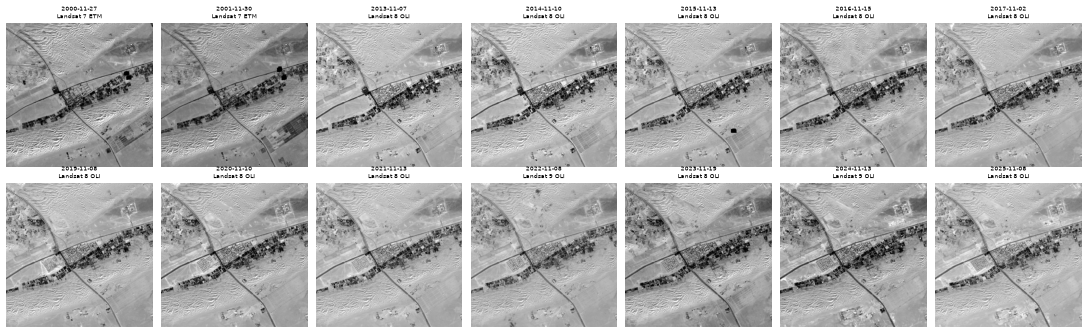

In [11]:
# WHAT THIS DOES: writes the observed frames (one per confirmed scene) with one common stretch, and records each one's real
# acquisition date, scene id, sensor, pixel size and the number of no-data pixels.
FRAMES.mkdir(parents=True, exist_ok=True)
for old in FRAMES.glob("*"):          # remove placeholder or stale frames; the manifest below lists every file written
    if old.suffix in (".png", ".jpg", ".jpeg", ".webp"):
        old.unlink()
OBS = []
pool = {}
INSTR = {"LANDSAT_7": "ETM+", "LANDSAT_8": "OLI", "LANDSAT_9": "OLI"}
for _, s in SCONF.iterrows():
    rho, meta, bad = load_scene(s.scene_id)
    OBS.append((s, rho, meta))
    pool.setdefault(INSTR[s.spacecraft], []).append(rho[INBOX & np.isfinite(rho)])
STRETCH = {}
for k_, v_ in pool.items():
    v_ = np.concatenate(v_)
    lo_s, hi_s = [float(x) for x in np.percentile(v_, P["stretch_pct"])]
    STRETCH[k_] = {"low": round(lo_s, 5), "high": round(hi_s, 5), "n_scenes": int(sum(INSTR[s.spacecraft] == k_ for s, _, _ in OBS)), "n_pixels": int(v_.size)}
    print(f"{k_} stretch (TOA reflectance / sin(sun elevation)): {lo_s:.4f} -> 1, {hi_s:.4f} -> 255 (percentiles {P['stretch_pct']} of {v_.size} in-box pixels, "
          f"{STRETCH[k_]['n_scenes']} scenes); gamma {P['gamma']}")
def u8_frame(rho, instr="OLI"):
    lo_s, hi_s = STRETCH[instr]["low"], STRETCH[instr]["high"]
    w, tr_ = fr.to_wgs84(rho, GRID, SITE["bbox"], P["frame_res_m"])
    nod = ~np.isfinite(w)
    u8 = fr.to_uint8(np.nan_to_num(w, nan=lo_s), lo_s, hi_s, P["gamma"]); u8[nod] = 0
    return u8, nod, tr_
SENSOR = {"LANDSAT_7": "Landsat 7 ETM+ B8", "LANDSAT_8": "Landsat 8 OLI B8", "LANDSAT_9": "Landsat 9 OLI-2 B8"}
observed = []
for s, rho, meta in OBS:
    u8, nod, TRW = u8_frame(rho, INSTR[s.spacecraft])
    fn = f"frames/obs_{s.date[:4]}.jpg"
    Image.fromarray(u8, "L").save(PUB / fn, quality=P["jpeg_quality"], optimize=True)
    observed.append({"year": int(s.date[:4]), "date": s.date, "scene_id": s.scene_id, "sensor": SENSOR[s.spacecraft], "pixel_m": 15, "file": fn,
                     "acquired_utc": f"{s.date}T{s.time_utc}Z", "sun_elevation_deg": round(float(s.sun_el), 2), "sun_azimuth_deg": round(float(s.sun_az), 2),
                     "nodata_pixels": int(nod.sum()), "stretch": INSTR[s.spacecraft], "clipped_pct": round(100 * float((u8 == 255).mean()), 2),
                     "bytes": (PUB / fn).stat().st_size})
FRAME_SHAPE = u8.shape
print(f"{len(observed)} observed frames, {FRAME_SHAPE[1]} x {FRAME_SHAPE[0]} px, {sum(o['bytes'] for o in observed) / 1e6:.2f} MB; "
      f"no-data pixels per frame: {[o['nodata_pixels'] for o in observed]}")
fig, axes = plt.subplots(2, int(math.ceil(len(observed) / 2)), figsize=(2.6 * int(math.ceil(len(observed) / 2)), 5.6))
for a, o in zip(axes.ravel(), observed):
    a.imshow(np.asarray(Image.open(PUB / o["file"])), cmap="gray", vmin=0, vmax=255); a.set_title(f"{o['date']}\n{o['sensor'][:13]}", fontsize=7); a.axis("off")
for a in axes.ravel()[len(observed):]:
    a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "03_observed_frames.png"); plt.show()

smoothed median field over the box: moving share 31.7 %; speed where moving: median 1.10, p90 1.60, max 2.67 m/yr


  case  year  share_of_box_moving_pct  median_m  p90_m  max_m  median_px  p90_px  max_px  share_of_box_moved_ge_1px_pct  mean_abs_gray_levels  share_pixels_changed_gt_10_levels_pct  kB
median  2030                     32.6      5.43   7.95  13.35       0.36    0.53    0.89                           0.00                  0.72                                   0.51 363
median  2035                     32.7     10.83  15.89  26.71       0.72    1.06    1.78                           4.45                  1.41                                   3.42 363
median  2040                     32.8     16.24  23.83  40.06       1.08    1.59    2.67                          18.96                  2.01                                   6.23 363
median  2045                     32.9     21.63  31.76  53.41       1.44    2.12    3.56                          23.92                  2.52                                   8.50 362
median  2050                     32.9     27.03  39.70  66.77       1.80   

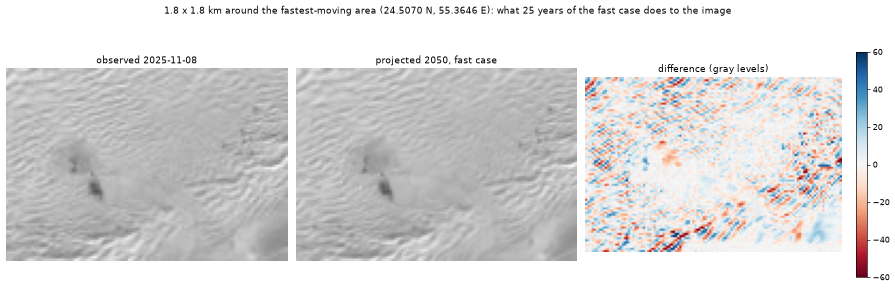

In [12]:
# WHAT THIS DOES: builds the smoothed motion field (median and fast case), advects the latest image to each projection year,
# writes transparent PNGs, and measures how far each frame moved the image.
use = VF.detected.values
spd = VF.speed_myr.values; sig = VF.sigma_myr.values
fast_scale = np.where(use, (spd + sig) / np.where(spd > 0, spd, 1), 0)
FIELD = {}
for case, scale in [("median", np.ones(len(VF))), ("fast", fast_scale)]:
    uE, uN = fr.window_field(VF.win_row.values, VF.win_col.values, np.nan_to_num(VF.east_myr.values) * scale, np.nan_to_num(VF.north_myr.values) * scale,
                             use, int(P2["step"]), (GRID.height, GRID.width), sigma_win=P["field_sigma_win"], median_win=P["field_median_win"])
    FIELD[case] = (uE, uN)
MOVE = ndimage.gaussian_filter((FREE & DETW).astype(float), 1.0)     # feathered: 1 on free sand under a detected window, 0 elsewhere
for case in FIELD:
    FIELD[case] = (FIELD[case][0] * MOVE, FIELD[case][1] * MOVE)
spd_pix = np.hypot(*FIELD["median"])
if (INBOX & (spd_pix > 0.01)).any():
    print(f"smoothed median field over the box: moving share {100 * (spd_pix[INBOX] > 0.01).mean():.1f} %; speed where moving: median "
          f"{np.median(spd_pix[INBOX & (spd_pix > 0.01)]):.2f}, p90 {np.percentile(spd_pix[INBOX & (spd_pix > 0.01)], 90):.2f}, max {spd_pix[INBOX].max():.2f} m/yr")
else:
    print("smoothed median field: nothing moves (no detected motion on free sand); projected frames equal the latest image")
u8_2025, _, _ = u8_frame(IMG0, INSTR[LATEST.spacecraft])
proj = {"median": [], "fast": []}
for case in ("median", "fast"):
    uE, uN = FIELD[case]
    for Y in P["frame_years"]:
        dty = float(Y - int(LATEST.date[:4]))          # November of year Y, same season as the latest scene
        adv = fr.advect(IMG0, uE, uN, dty, RES)
        u8, nod, _ = u8_frame(adv, INSTR[LATEST.spacecraft])
        rgba = np.dstack([u8, np.where(nod, 0, 255).astype(np.uint8)])
        fn = f"frames/prj_{'med' if case == 'median' else 'fast'}_{Y}.png"
        Image.fromarray(rgba, "LA").save(PUB / fn, optimize=True)
        disp = np.hypot(uE, uN)[INBOX] * dty
        mv = disp > 0.01
        diff = np.abs(u8.astype(int) - u8_2025.astype(int))[(~nod) & (u8_2025 > 0)]
        proj[case].append({"year": Y, "file": fn, "from_date": LATEST.date, "years_advected": dty,
                           "displacement": {"share_of_box_moving_pct": round(100 * float(mv.mean()), 1),
                                            "median_m": round(float(np.median(disp[mv])), 2) if mv.any() else 0.0,
                                            "p90_m": round(float(np.percentile(disp[mv], 90)), 2) if mv.any() else 0.0,
                                            "max_m": round(float(disp.max()), 2),
                                            "median_px": round(float(np.median(disp[mv]) / RES), 2) if mv.any() else 0.0,
                                            "p90_px": round(float(np.percentile(disp[mv], 90) / RES), 2) if mv.any() else 0.0,
                                            "max_px": round(float(disp.max() / RES), 2),
                                            "share_of_box_moved_ge_1px_pct": round(100 * float((disp >= RES).mean()), 2)},
                           "image_change_vs_latest_observed": {"mean_abs_gray_levels": round(float(diff.mean()), 2),
                                                               "share_pixels_changed_gt_10_levels_pct": round(100 * float((diff > 10).mean()), 2)},
                           "bytes": (PUB / fn).stat().st_size})
PT = pd.DataFrame([{"case": c_, "year": e["year"], **e["displacement"], **e["image_change_vs_latest_observed"], "kB": round(e["bytes"] / 1e3)} for c_ in proj for e in proj[c_]])
print(PT.to_string(index=False))
# the 2050 fast-case frame against the latest observed frame, in a moving area
k_mv = np.unravel_index(np.argmax(ndimage.uniform_filter(np.hypot(*FIELD["fast"]) * INBOX, 40)), (GRID.height, GRID.width))
cxm, cym = GRID.xy(*k_mv)
lonm, latm = TO_LL(cxm, cym)
w_obs = np.asarray(Image.open(PUB / observed[-1]["file"])).astype(float)
w_f50 = np.asarray(Image.open(PUB / proj["fast"][-1]["file"]))[..., 0].astype(float)
TRW_inv = ~TRW
ccm, rrm = TRW_inv * (lonm, latm); rrm, ccm = int(rrm), int(ccm)
sl = (slice(max(0, rrm - 60), rrm + 60), slice(max(0, ccm - 60), ccm + 60))
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
axes[0].imshow(w_obs[sl], cmap="gray", vmin=0, vmax=255); axes[0].set_title(f"observed {observed[-1]['date']}")
axes[1].imshow(w_f50[sl], cmap="gray", vmin=0, vmax=255); axes[1].set_title(f"projected 2050, fast case")
im = axes[2].imshow(w_f50[sl] - w_obs[sl], cmap="RdBu", vmin=-60, vmax=60); axes[2].set_title("difference (gray levels)"); plt.colorbar(im, ax=axes[2], fraction=0.04)
for a in axes: a.axis("off")
plt.suptitle(f"1.8 x 1.8 km around the fastest-moving area ({latm:.4f} N, {lonm:.4f} E): what 25 years of the fast case does to the image")
plt.tight_layout(); plt.savefig(OUT / "03_projected_vs_observed.png"); plt.show()

In [13]:
# WHAT THIS DOES: writes frames/manifest.json (§4 format plus the frame grid, stretch, method and per-frame displacement).
lat_c = math.radians((b["south"] + b["north"]) / 2)
manifest = {
    "bounds": {"west": b["west"], "south": b["south"], "east": b["east"], "north": b["north"]},
    "observed": observed,
    "projected_median": proj["median"],
    "projected_fast": proj["fast"],
    "crs": "EPSG:4326", "width": FRAME_SHAPE[1], "height": FRAME_SHAPE[0],
    "pixel_deg": [round((b["east"] - b["west"]) / FRAME_SHAPE[1], 9), round((b["north"] - b["south"]) / FRAME_SHAPE[0], 9)],
    "pixel_m_approx": [round((b["east"] - b["west"]) / FRAME_SHAPE[1] * 111320 * math.cos(lat_c), 2), round((b["north"] - b["south"]) / FRAME_SHAPE[0] * 110574, 2)],
    "bounds_note": "The outer edges of every image are exactly these bounds (pixel corners, not centres). Images were resampled bilinearly from the 15 m UTM grid (EPSG:%s)." % SITE["epsg"],
    "stretch": {"quantity": "Landsat B8 top-of-atmosphere reflectance / sin(sun elevation)", "per_instrument": STRETCH,
                "gray_levels": "1-255 linear (0 = no data)", "gamma": P["gamma"],
                "rule": (f"one stretch per instrument, the same for every year of that instrument: percentiles {list(P['stretch_pct'])} of all in-box pixels of its scenes. "
                         "ETM+ pan (0.52-0.90 um) includes near-infrared where sand is brighter than in OLI/OLI-2 pan (0.50-0.68 um), so ETM+ vs OLI brightness differences "
                         "are partly instrumental. Projected frames use the stretch of the latest scene's instrument.")},
    "observed_format": "JPEG, grayscale, opaque (no-data would be black; see nodata_pixels)",
    "projected_format": "PNG, grayscale + alpha (alpha 0 = no data)",
    "masking": "Landsat QA_PIXEL fill, dilated cloud, cirrus, cloud and cloud shadow (dilated by one 15 m pixel) are no-data",
    "projection_method": ("Semi-Lagrangian advection of the latest observed image along the measured 2013-%s dune-motion field: output(x) = image(x - u(x) * years), "
                          "cubic interpolation. u = velocity of windows with detected motion only (0 below the detection limit, in masked/non-dune areas and outside "
                          "dune windows), 3x3-window median filter, Gaussian smoothing (sigma = 120 m), bilinear to 15 m, times a feathered free-sand mask. "
                          "median case = measured velocity; fast case = same heading at speed + 1 sigma (84th percentile of the speed). "
                          "Assumes the 2013-2025 motion continues unchanged; dunes do not deform, merge, grow or get removed." % LATEST.date[:4]),
    "projection_reading_note": (f"These frames change very little: by 2050 the median case moves {proj['median'][-1]['displacement']['share_of_box_moving_pct']} % of the box, "
                                f"by a median {proj['median'][-1]['displacement']['median_m']} m ({proj['median'][-1]['displacement']['median_px']} px) and at most "
                                f"{proj['median'][-1]['displacement']['max_m']} m; the fast case at most {proj['fast'][-1]['displacement']['max_m']} m. "
                                f"The other {round(100 - proj['median'][-1]['displacement']['share_of_box_moving_pct'], 1)} % of the box is drawn unchanged, because motion there is below the detection limit or the ground is not dune sand. "
                                "The small change is the measurement, not a rendering problem."),
    "warp_test": WARP_TEST,
    "generated_by": "pipeline/03_threats_and_frames.ipynb",
}
(FRAMES / "manifest.json").write_text(json.dumps(manifest, indent=1) + "\n")
print(f"manifest: {len(observed)} observed, {len(proj['median'])} + {len(proj['fast'])} projected frames; bounds {manifest['bounds']}")
print(manifest["projection_reading_note"])

manifest: 14 observed, 5 + 5 projected frames; bounds {'west': 55.29, 'south': 24.42, 'east': 55.39, 'north': 24.51}
These frames change very little: by 2050 the median case moves 32.9 % of the box, by a median 27.03 m (1.8 px) and at most 66.77 m; the fast case at most 72.19 m. The other 67.1 % of the box is drawn unchanged, because motion there is below the detection limit or the ground is not dune sand. The small change is the measurement, not a rendering problem.


## 4 · Targets file, summary and sources

In [14]:
# WHAT THIS DOES: writes targets.geojson (WGS84) with the §4 fields and the additive reach details.
def ll(geom, nd=6):
    gg = rasters.reproject_geom(TO_LL, geom)
    return json.loads(json.dumps(mapping(shapely.set_precision(gg, 10 ** -nd))))
tfeat = []
for t in TG:
    pr = {"id": t["id"], "name": t["name"], "type": t["type"], "hit_year_min": t["hit_year_min"], "hit_year_max": t["hit_year_max"],
          "hit_year_med": t["hit_year_med"], "hit_year_max_uncapped": t["hit_year_max_uncapped"], "threat_status": t["status"],
          "threat_by_projection_end": bool(t["hit_year_min"] is not None and t["hit_year_min"] <= P["projection_end"]),
          "gap_m": t["gap_m"], "approach": t["approach"], "borders_free_sand": t["borders_free_sand"], "free_sand_gap_m": t["free_sand_gap_m"],
          "class": t["cls"], "source": t["source"]}
    if t["type"] == "road":
        pr.update(length_m=t["size"], half_width_m=t["half_width_m"], osm_way_ids=t["osm_ways"])
    else:
        pr.update(area_ha=t["size"])
        if t["osm_ways"]:
            pr["osm_id"] = t["osm_ways"][0]
    geom = t["line"] if t["type"] == "road" else t["footprint"]
    tfeat.append({"type": "Feature", "properties": pr, "geometry": ll(geom)})
tnote = (f"Targets inside the {SITE['name']} box. Roads and built-up areas: OpenStreetMap (c) OpenStreetMap contributors, ODbL, via the Overpass API "
         f"(database timestamp {OSM_BASE}, retrieved {OSM_RETRIEVED}); roads split into segments <= {P['road_segment_m']} m, geometry = centre line, footprint = "
         f"centre line +- half_width_m. Farms/plantations: NASA HLS L30+S30 v2.0 median NDVI {t_a} to {t_b} (end exclusive) >= {FARM_THR:.3f}, 30 m, >= {P['farm_min_area_ha']} ha. "
         "hit_year_min/max: years in which migrating dune sand (measured Landsat 8/9 2013-2025 motion, detected windows only) is projected to reach the footprint: "
         "min = fast case (speed + 1 sigma) over the shortest plausible gap, max = slow case (speed - 1 sigma) over the longest; null = not reached by 2100 along the "
         "measured heading (hit_year_max is also null when the slow case arrives after 2100: see hit_year_max_uncapped). Excludes blowing sand (see borders_free_sand), "
         "sand already on the target, motion below the detection limit and dune deformation. Computed by pipeline/03_threats_and_frames.ipynb.")
TJ = {"type": "FeatureCollection", "note": tnote,
      "osm": {"overpass_url": tg.OVERPASS_URL, "query": OSM_Q, "timestamp_osm_base": OSM_BASE, "retrieved_utc": OSM_RETRIEVED, "license": "ODbL 1.0"},
      "features": tfeat}
(PUB / "targets.geojson").write_text(json.dumps(TJ, separators=(",", ":")) + "\n")
print(f"wrote {len(tfeat)} targets -> {(PUB / 'targets.geojson').relative_to(config.ROOT)} ({(PUB / 'targets.geojson').stat().st_size / 1e3:.0f} kB)")

wrote 873 targets -> public/data/sweihan/targets.geojson (644 kB)


In [15]:
# WHAT THIS DOES: writes summary.json (§4 fields with real values plus additive detail), with an honest validation block.
vs = QC2["velocity_summary"]; nd_ = QC2["noise_and_detection"]; dun = QC2["dunes"]; hls = QC2["hls_second_dataset"]; ph = QC2["physics"]
# site-specific interpretive text (published reference, wind and second-dataset notes, limits) lives in the site notes as
# templates filled from this run's numbers, so this notebook carries no single site's conclusions
TXT_P = config.PIPELINE / "site_notes" / SID / "03_summary_text.json"
TXT = json.loads(TXT_P.read_text()) if TXT_P.exists() else {}
WS = json.loads((PUB / "wind_summary.json").read_text())
dj = json.loads((PUB / "dunes.geojson").read_text())
cls_counts = {c_: sum(f["properties"]["class"] == c_ for f in dj["features"]) for c_ in ("stable", "slow", "active", "fast")}
detv = VF[VF.detected]
agree = wind.angle_diff(detv.heading_deg.values, float(WS["RDD_deg"]))
FMT = dict(vs=vs, nd=nd_, ph=ph, s30=hls.get("HLSS30", {}), l30=hls.get("HLSL30", {}), ws=WS, qc=QC2, P=P, n_dunes=len(dj["features"]),
           pct_below=100 - vs["pct_detected_of_valid"],
           tt=dict(n_targets=len(TG), n_reached_by_2050=int((TT.hit_year_min <= P["projection_end"]).sum()), n_reached_by_2100=int(TT.hit_year_min.notna().sum()),
                   n_at_edge=int((TT.status == "sand_at_edge_now").sum())))
def fill(x):
    return {k_: fill(v_) for k_, v_ in x.items()} if isinstance(x, dict) else ([fill(v_) for v_ in x] if isinstance(x, list) else x.format_map(FMT))
rej01 = pd.read_csv(OUT / "scene_rejections.csv") if (OUT / "scene_rejections.csv").exists() else pd.DataFrame()
n_rej = int(((rej01.get("month") == CONF["month"]) & rej01.scene_id.notna() & ~rej01.reason.str.startswith("passed", na=False)).sum()) if len(rej01) else 0
s30, l30 = hls.get("HLSS30", {}), hls.get("HLSL30", {})
first_oli = SCONF[SCONF.spacecraft != "LANDSAT_7"].iloc[0]
by_type = {ty: {"n": int((TT.type == ty).sum()), "reached_by_2050": int(((TT.type == ty) & (TT.hit_year_min <= P["projection_end"])).sum()),
                "reached_by_2100": int(((TT.type == ty) & TT.hit_year_min.notna()).sum()),
                "sand_at_edge_now": int(((TT.type == ty) & (TT.status == "sand_at_edge_now")).sum()),
                "borders_free_sand": int(((TT.type == ty) & TT.borders_free_sand).sum())} for ty in ("road", "farm", "building")}
earliest = [{"id": r_.id, "name": r_.name, "type": r_.type, "status": r_.status, "hit_year_min": int(r_.hit_year_min), "hit_year_med": int(r_.hit_year_med),
             "hit_year_max": None if pd.isna(r_.hit_year_max) else int(r_.hit_year_max), "hit_year_max_uncapped": int(r_.hit_year_max_uncapped), "gap_m": r_.gap_m}
            for r_ in fl.head(10).itertuples()]
summary = {
    "aoi_name": SITE["name"], "aoi_bounds": SITE["bbox"],
    "baseline": {"start_date": first_oli.date, "end_date": LATEST.date, "years": round(float(LATEST.t - first_oli.t), 2),
                 "note": f"velocities from the Landsat 8/9 OLI network ({vs['n_oli_scenes']} November scenes, {vs['n_oli_pairs']} pairs); the Landsat 7 scenes "
                         f"({', '.join(SCONF[SCONF.spacecraft == 'LANDSAT_7'].date)}) are used only as a long-baseline check"},
    "n_dunes": len(dj["features"]), "counts_by_class": cls_counts, "n_threat": int(sum(f["properties"]["threat"] for f in dj["features"])),
    "speed_median_myr": round(vs["detected_speed_median_myr"], 2), "speed_p10_myr": round(vs["detected_speed_p10_p90_myr"][0], 2),
    "speed_p90_myr": round(vs["detected_speed_p10_p90_myr"][1], 2),
    "uncertainty_myr": round(float(np.median(VF.sigma_myr[VF.valid])), 2),
    "mean_wind_agreement_deg": round(float(np.mean(agree)), 1) if agree.size else None,
    "speed_note": (f"speeds are of the {vs['n_detected']} dune windows (480 m) with detected motion ({vs['pct_detected_of_valid']} % of {vs['n_valid_dune_windows']} valid); "
                   f"the other {vs['n_valid_dune_windows'] - vs['n_detected']} move slower than their detection limit (median {nd_['detection_limit_median_myr']:.2f} m/yr) "
                   f"and are not in these statistics. Max detected {vs['detected_speed_range_myr'][1]:.2f} m/yr. uncertainty_myr = median calibrated 1-sigma per component."),
    "detection_limit_myr": round(nd_["detection_limit_median_myr"], 2),
    "wind_agreement_note": (f"mean |heading - RDD| over detected windows, RDD {WS['RDD_deg']} deg (MERRA-2 2000-2024). The wind regime is bimodal (RDP/DP {WS['RDP_DP']}): "
                            f"the field-median heading {ph['field_median_heading_deg']} deg is {ph['field_heading_minus_modes_deg'][1]} deg from the northward (southerly-wind) mode "
                            f"and {ph['field_heading_minus_RDD_deg']} deg from RDD; per-window median difference {ph['per_window_abs_heading_minus_RDD_median_deg']} deg."),
    "validation": {
        "published": {"reference": "Fareaa 2025 UAEU thesis",
                      "their_value": "3.32 m average migration, peaking in 2019 (abstract; Sentinel-2, COSI-Corr, 2018-2020); time base not stated",
                      "our_value": "no numeric comparison",
                      "note": ("Context only. The abstract gives '3.32 m' with no time base (per year, per month or per image pair), no area and no statistic, and the full "
                               "text could not be read, so the number cannot be compared with a rate in m/yr (the two readings differ about 12-fold). It is also not "
                               "confirmed that the thesis field ('Seih Al-Lahma' in its Arabic abstract) is this box. https://scholarworks.uaeu.ac.ae/all_theses/1432")},
        "second_dataset": {"dataset": "NASA HLS L30/S30",
                           "period": f"S30: {s30.get('years')}; L30: {l30.get('years')}",
                           "their_value": (f"HLS S30 (Sentinel-2, independent): field median {s30.get('field_median_speed_hls_myr')} m/yr toward {s30.get('field_median_heading_hls_deg')} deg; "
                                           f"per-window correlation with Landsat r = {s30.get('corr_E')} (E), {s30.get('corr_N')} (N); its detection limit {s30.get('hls_detection_limit_median_myr')} m/yr, "
                                           f"motion detected in {s30.get('hls_pct_valid_windows_detected')} % of windows. HLS L30 (same Landsat instruments, not independent): "
                                           f"{l30.get('field_median_speed_hls_myr')} m/yr toward {l30.get('field_median_heading_hls_deg')} deg, r = {l30.get('corr_E')}/{l30.get('corr_N')}"),
                           "our_value": (f"Landsat pan 15 m over the same years: field median {s30.get('field_median_speed_landsat_myr')} m/yr toward {s30.get('field_median_heading_landsat_deg')} deg "
                                         f"(S30 years); {l30.get('field_median_speed_landsat_myr')} m/yr toward {l30.get('field_median_heading_landsat_deg')} deg (L30 years)"),
                           "note": (f"The independent Sentinel-2 check agrees only weakly: speeds about half of Landsat's and headings {s30.get('heading_difference_deg')} deg apart at field "
                                    f"level, per-window r {s30.get('corr_E')}/{s30.get('corr_N')}. At 30 m its detection limit ({s30.get('hls_detection_limit_median_myr')} m/yr) is above most measured "
                                    f"speeds, so it can confirm little; where Landsat speeds exceed twice the detection limit "
                                    f"({s30.get('windows_where_landsat_speed_gt_2x_detection_limit', {}).get('n')} windows) headings differ by a median "
                                    f"{s30.get('windows_where_landsat_speed_gt_2x_detection_limit', {}).get('median_heading_diff_deg')} deg. HLS L30 agrees better "
                                    f"(heading within {l30.get('heading_difference_deg')} deg, speed {l30.get('field_median_speed_hls_myr')} vs {l30.get('field_median_speed_landsat_myr')} m/yr) "
                                    "but uses the same Landsat instruments, so it only shows the result survives a different band, resolution and processing.")}},
    "data_handling": {"scenes_rejected": n_rej, "cloud_masking": "QA_PIXEL / Fmask",
                      "windows_rejected_pct": round(QC2["rejections"]["pct_dune_windows_rejected"], 2),
                      "notes": (f"{n_rej} {CONF['month']} candidate scenes rejected in notebook 01 (cloud/shadow/haze/coverage; listed in pipeline/outputs/{SID}/scene_rejections.csv); "
                                "Landsat 7 used only before the 31 May 2003 SLC failure. Clouds/shadows: Landsat QA_PIXEL bits 0-4 (dilated 1 px), HLS Fmask bits 1-3. "
                                f"Of {QC2['rejections']['windows']['all windows on the grid']} tracking windows, {QC2['rejections']['windows']['centre outside the box']} lie outside the box and "
                                f"{QC2['rejections']['windows']['inside box, > 25 % non-dune mask']} are mostly non-dune (vegetation, WorldCover, OSM, hand-drawn change areas); of the "
                                f"{vs['n_dune_windows']} dune windows {QC2['rejections']['pct_dune_windows_rejected']} % had too few valid pairs. Window-pair observations rejected: "
                                f"{QC2['rejections']['pct_observations_rejected']} % (weak match below the false-match threshold, displacement beyond the reliable range, network outliers).")},
    "limits": [
        f"Speeds are slow: detected dune windows move a median {vs['detected_speed_median_myr']:.2f} m/yr (10-90 %: {vs['detected_speed_p10_p90_myr'][0]:.2f}-{vs['detected_speed_p10_p90_myr'][1]:.2f}, max {vs['detected_speed_range_myr'][1]:.2f}), "
        f"i.e. roughly 10-30 m in 25 years; {100 - vs['pct_detected_of_valid']:.0f} % of valid dune windows move below the detection limit (median {nd_['detection_limit_median_myr']:.2f} m/yr) and have no measured direction.",
        "Reach years forecast the migration of dune forms (slip-face advance), not wind-blown sand crossing a road, which happens wherever a road borders loose sand, whatever the dunes do (see borders_free_sand in targets.geojson).",
        "At these speeds the position of the sand edge matters as much as the speed: a 15 m pixel is about 20 years of motion at 0.7 m/yr, so reach years for targets near the sand carry an edge uncertainty of +-7.5 m plus the outline uncertainty of the target.",
        f"Most targets are not reached by {P['projection_end']}; targets flagged 'sand at edge now' already have migrating sand within that edge uncertainty.",
        "The projection is advection along the measured 2013-2025 motion, assuming those conditions continue; it does not model dune deformation, merging, splitting or growth.",
        "Vegetation, windbreaks, sand fences, levelling, construction and climate change alter the outcome.",
        "Motion is measured in 480 m windows: it is the motion of the small dunes (spacing ~70-90 m) and sand sheets inside, not of a single dune body.",
        f"Only {len(dj['features'])} large dunes (14-72 m high) are outlined, from NASADEM (February 2000) shifted to 2025; the small dunes that carry most of the motion are represented by the velocity grid, not by polygons.",
        "The independent Sentinel-2 (HLS S30) check agrees only weakly; HLS L30 agrees better but uses the same Landsat instruments.",
        "The published UAEU study is context only: its '3.32 m' has no stated time base, so no numeric comparison is made.",
        "MERRA-2 wind is a ~0.5 x 0.625 deg reanalysis of hourly means; absolute drift potential is approximate and the regime is bimodal.",
        "Farms are vegetated plots (HLS NDVI, last year) and built-up targets come from OpenStreetMap, where few buildings are mapped here; unmapped or abandoned plots are not targets.",
        "Results are valid for this box and 2013-2025 only; nothing outside the box is assessed.",
    ],
    "threat": {
        "reach_definition": ("Migrating dune sand (free sand inside a window whose dune-form migration is detected), carried along its measured heading at its measured speed, "
                             "arrives at the edge of the target footprint (road: OSM centre line +- class half width incl. shoulders; farm: HLS vegetated outline; built-up: OSM outline)."),
        "excludes": ["wind-blown sand crossing or settling on a target", "sand already on the target", "motion below the detection limit (no direction: never a hit)",
                     "dune deformation, merging, growth, levelling or stabilisation", "anything outside the box"],
        "speeds": "median = measured window speed v; fast = v + sigma; slow = v - sigma (sigma = calibrated per-component 1-sigma; 84th/16th percentiles of the speed)",
        "years": ("hit_year_min = floor(t0 + gap_lo / fast); hit_year_max = ceil(t0 + gap_hi / slow); gap = distance from the source pixel centre to the footprint along the heading "
                  "minus 7.5 m, +-(7.5 m + outline uncertainty: roads/buildings 5 m, farms 15 m); t0 = %s; earliest over all sand reaching the target; null if the fast case "
                  "does not arrive by %d" % (LATEST.date, P["horizon"])),
        "targets_by_type": by_type,
        "n_targets": len(TG), "n_reached_by_2050": int((TT.hit_year_min <= P["projection_end"]).sum()), "n_reached_by_2100": int(TT.hit_year_min.notna().sum()),
        "n_sand_at_edge_now": int((TT.status == "sand_at_edge_now").sum()),
        "n_possible_within_direction_uncertainty": int((TT.status == "possible_within_direction_uncertainty").sum()),
        "earliest": earliest,
    },
    "frames": {"n_observed": len(observed), "projected_years": P["frame_years"],
               "median_case_2050_displacement": proj["median"][-1]["displacement"], "fast_case_2050_displacement": proj["fast"][-1]["displacement"]},
    "generated_by": "pipeline/03_threats_and_frames.ipynb (from notebook 02's pipeline/outputs/%s/02_qc_summary.json and 02_velocity_field.csv)" % SID,
}
# The interpretive texts written inline above were written for the first site (seih_al_hama). Each site's own versions, written
# after looking at that site's results, are in pipeline/site_notes/<site>/03_summary_text.json and replace them here (the
# seih_al_hama file reproduces the inline texts exactly).
if TXT:
    summary["wind_agreement_note"] = fill(TXT["wind_agreement_note"])
    summary["validation"]["published"] = fill(TXT["published"])
    summary["validation"]["second_dataset"]["note"] = fill(TXT["second_dataset_note"])
    summary["limits"] = fill(TXT["limits"])
(PUB / "summary.json").write_text(json.dumps(summary, indent=1, default=lambda o: None if isinstance(o, float) and not np.isfinite(o) else o) + "\n")
print(json.dumps({k_: summary[k_] for k_ in ("n_dunes", "counts_by_class", "n_threat", "speed_median_myr", "speed_p10_myr", "speed_p90_myr", "uncertainty_myr", "mean_wind_agreement_deg")}, indent=1))
print(json.dumps(summary["threat"]["targets_by_type"], indent=1))

{
 "n_dunes": 12,
 "counts_by_class": {
  "stable": 2,
  "slow": 7,
  "active": 3,
  "fast": 0
 },
 "n_threat": 0,
 "speed_median_myr": 1.15,
 "speed_p10_myr": 0.55,
 "speed_p90_myr": 1.82,
 "uncertainty_myr": 0.15,
 "mean_wind_agreement_deg": 15.6
}
{
 "road": {
  "n": 735,
  "reached_by_2050": 11,
  "reached_by_2100": 11,
  "sand_at_edge_now": 9,
  "borders_free_sand": 273
 },
 "farm": {
  "n": 59,
  "reached_by_2050": 10,
  "reached_by_2100": 10,
  "sand_at_edge_now": 9,
  "borders_free_sand": 40
 },
 "building": {
  "n": 79,
  "reached_by_2050": 3,
  "reached_by_2100": 3,
  "sand_at_edge_now": 0,
  "borders_free_sand": 8
 }
}


In [16]:
# WHAT THIS DOES: writes sources.json: every dataset actually used, with version, dates, place, pixel size, link and DOI.
# The DOIs and links were checked online on 2026-11-14 (doi.org resolves each to the dataset's own landing page).
place = f"{SITE['name']} box (W {b['west']}, S {b['south']}, E {b['east']}, N {b['north']})"
l7 = SCONF[SCONF.spacecraft == "LANDSAT_7"]; oli = SCONF[SCONF.spacecraft != "LANDSAT_7"]
aux = SC[SC.role == "illumination_test"]
hls_sc = pd.read_csv(OUT / "02_hls_scenes.csv")
sources = [
    {"name": "Landsat 7 ETM+ Collection 2 Level-1 (Tier 1)", "provider": "NASA / USGS", "version": "Collection 2",
     "used_for": "observed timeline frames and the long-baseline motion check (B8 panchromatic); vegetation mask (B3/B4 TOA NDVI)",
     "dates": list(l7.date), "scene_ids": list(l7.scene_id), "place": f"{place}; WRS-2 path {SITE['wrs_path']} row {SITE['wrs_row']}", "pixel": "15 m (B8), 30 m (QA_PIXEL, B3/B4)",
     "access": "Google Earth Engine LANDSAT/LE07/C02/T1", "link": "https://www.usgs.gov/landsat-missions/landsat-collection-2-level-1-data",
     "doi": "https://doi.org/10.5066/P9TU80IG", "doi_checked": "resolves to 'Landsat 7 Enhanced Thematic Mapper Plus Collection 2 Level-1 Data' (USGS EROS)"},
    {"name": "Landsat 8-9 OLI/TIRS Collection 2 Level-1 (Tier 1)", "provider": "NASA / USGS", "version": "Collection 2",
     "used_for": "dune motion (B8 panchromatic, velocity network), observed timeline frames, projected frames (from the latest scene), illumination test, vegetation mask (B4/B5 TOA NDVI)",
     "dates": list(oli.date), "scene_ids": list(oli.scene_id), "illumination_test_dates": list(aux.date),
     "place": f"{place}; WRS-2 path {SITE['wrs_path']} row {SITE['wrs_row']}", "pixel": "15 m (B8), 30 m (QA_PIXEL, B4/B5)",
     "access": "Google Earth Engine LANDSAT/LC08/C02/T1, LANDSAT/LC09/C02/T1", "link": "https://www.usgs.gov/landsat-missions/landsat-collection-2-level-1-data",
     "doi": "https://doi.org/10.5066/P975CC9B", "doi_checked": "resolves to 'Landsat 8-9 Operational Land Imager and Thermal Infrared Sensor Collection 2 Level-1 Data' (USGS EROS)"},
    {"name": "HLS Sentinel-2 MSI Surface Reflectance (HLSS30) v2.0", "provider": "NASA LP DAAC", "version": "2.0",
     "used_for": "independent second-dataset motion check (B4 red, Fmask); farm/plantation NDVI (B8A, B4) over the last year",
     "dates": sorted(hls_sc[hls_sc["product"] == "HLSS30"].date.str[:10].tolist()), "farm_composite_period": f"{t_a} to {t_b} (end exclusive), {len(FM['granules']['HLSS30'])} granules",
     "place": f"{place}; MGRS tile {SITE['hls_tile']}", "pixel": "30 m", "access": "Google Earth Engine NASA/HLS/HLSS30/v002",
     "link": "https://www.earthdata.nasa.gov/data/catalog/lpcloud-hlss30-2.0", "doi": "https://doi.org/10.5067/HLS/HLSS30.002",
     "doi_checked": "resolves to 'HLS Sentinel-2 Multi-spectral Instrument Surface Reflectance Daily Global 30m v2.0' (NASA Earthdata)"},
    {"name": "HLS Landsat OLI Surface Reflectance and TOA Brightness (HLSL30) v2.0", "provider": "NASA LP DAAC", "version": "2.0",
     "used_for": "same-instrument motion check (B4 red, Fmask); farm/plantation NDVI (B5, B4) over the last year",
     "dates": sorted(hls_sc[hls_sc["product"] == "HLSL30"].date.str[:10].tolist()), "farm_composite_period": f"{t_a} to {t_b} (end exclusive), {len(FM['granules']['HLSL30'])} granules",
     "place": f"{place}; MGRS tile {SITE['hls_tile']}", "pixel": "30 m", "access": "Google Earth Engine NASA/HLS/HLSL30/v002",
     "link": "https://www.earthdata.nasa.gov/data/catalog/lpcloud-hlsl30-2.0", "doi": "https://doi.org/10.5067/HLS/HLSL30.002",
     "doi_checked": "resolves to 'HLS Landsat Operational Land Imager Surface Reflectance and TOA Brightness Daily Global 30m v2.0' (NASA Earthdata)"},
    {"name": "MERRA-2 tavg1_2d_slv_Nx (M2T1NXSLV) U10M, V10M", "provider": "NASA GMAO / GES DISC", "version": "5.12.4",
     "used_for": "wind drift potential (Fryberger DP, RDP, RDD) and the interannual wind check", "dates": ["2000-01-01/2024-12-31"],
     "place": f"MERRA-2 grid cell nearest the box centre ({WS['location']['lat']} N, {WS['location']['lon']} E)", "pixel": "0.5 x 0.625 deg",
     "access": "Google Earth Engine NASA/GSFC/MERRA/slv/2", "link": "https://disc.gsfc.nasa.gov/datasets/M2T1NXSLV_5.12.4/summary",
     "doi": "https://doi.org/10.5067/VJAFPLI1CSIV", "doi_checked": "resolves to 'MERRA-2 tavg1_2d_slv_Nx ... V5.12.4 (M2T1NXSLV)' (NASA Earthdata)"},
    {"name": "MERRA-2 tavg1_2d_aer_Nx (M2T1NXAER) TOTEXTTAU, DUEXTTAU", "provider": "NASA GMAO / GES DISC", "version": "5.12.4",
     "used_for": "haze indicator for scene screening (aerosol optical depth at the acquisition hour)", "dates": ["acquisition hours of the candidate scenes, 2000-2025"],
     "place": "MERRA-2 grid cell of the box", "pixel": "0.5 x 0.625 deg", "access": "Google Earth Engine NASA/GSFC/MERRA/aer/2",
     "link": "https://disc.gsfc.nasa.gov/datasets/M2T1NXAER_5.12.4/summary", "doi": "https://doi.org/10.5067/KLICLTZ8EM9D",
     "doi_checked": "resolves to 'MERRA-2 tavg1_2d_aer_Nx ... V5.12.4 (M2T1NXAER)' (NASA Earthdata)"},
    {"name": "NASA POWER hourly (MERRA-2 based) WS10M/WD10M, U10M/V10M", "provider": "NASA Langley Research Center (POWER project)", "version": "POWER API v2 (as served 2026-11)",
     "used_for": "processing cross-check of the MERRA-2 wind numbers", "dates": ["2001-01-01/2024-12-31"], "place": "box centroid", "pixel": "0.5 x 0.625 deg (MERRA-2 source)",
     "link": "https://power.larc.nasa.gov/", "doi": None, "doi_checked": "NASA POWER has no dataset DOI; the link (project home) was checked"},
    {"name": "NASADEM Merged DEM Global 1 arc second (NASADEM_HGT) V001", "provider": "NASA JPL / LP DAAC", "version": "001",
     "used_for": "dune outlines and heights (SRTM radar, February 2000)", "dates": ["2000-02-11/2000-02-22"], "place": place, "pixel": "1 arc-second (~30 m)",
     "access": "Google Earth Engine NASA/NASADEM_HGT/001", "link": "https://www.earthdata.nasa.gov/data/catalog/lpcloud-nasadem-hgt-001",
     "doi": "https://doi.org/10.5067/MEaSUREs/NASADEM/NASADEM_HGT.001", "doi_checked": "resolves to 'NASADEM Merged DEM Global 1 arc second V001' (NASA Earthdata)"},
    {"name": "ESA WorldCover 10 m 2021 v200", "provider": "European Space Agency (not NASA)", "version": "v200",
     "used_for": "non-dune mask (tree cover, cropland, built-up, water) and the farm cross-check", "dates": ["2021"], "place": place, "pixel": "10 m",
     "access": "Google Earth Engine ESA/WorldCover/v200", "link": "https://esa-worldcover.org/", "doi": "https://doi.org/10.5281/zenodo.7254221",
     "doi_checked": "resolves to 'ESA WorldCover 10 m 2021 v200' (Zenodo)"},
    {"name": "OpenStreetMap", "provider": "OpenStreetMap contributors (ODbL 1.0)", "version": f"database timestamp {OSM_BASE}",
     "used_for": "targets: roads and built-up areas (Overpass API); non-dune mask (notebook 02)", "dates": [OSM_BASE[:10]], "retrieved": OSM_RETRIEVED,
     "place": place, "pixel": "vector", "link": "https://www.openstreetmap.org/copyright", "doi": None,
     "doi_checked": "no DOI; licence page checked. Query recorded in targets.geojson"},
]
(PUB / "sources.json").write_text(json.dumps(sources, indent=1) + "\n")
print(f"wrote {len(sources)} sources -> {(PUB / 'sources.json').relative_to(config.ROOT)}")

wrote 10 sources -> public/data/sweihan/sources.json


In [17]:
# WHAT THIS DOES: rebuilds public/data/sites.json and checks every §4 file of this site against the contract and against each
# other (same dune ids, counts, manifest files, unique target ids, no placeholder left), plus the size budget.
idx = site_index.write_index()
me = next(s for s in idx["sites"] if s["id"] == SID)
print("site index:", me["status"], me["files"])
num = (int, float)
def isnum(x): return isinstance(x, num) and not isinstance(x, bool)
dj = json.loads((PUB / "dunes.geojson").read_text()); d0 = json.loads((PUB / "dunes_2000.geojson").read_text())
vj = json.loads((PUB / "vectors.geojson").read_text()); tj = json.loads((PUB / "targets.geojson").read_text())
mf = json.loads((FRAMES / "manifest.json").read_text()); sm = json.loads((PUB / "summary.json").read_text())
wsj = json.loads((PUB / "wind_summary.json").read_text()); srcj = json.loads((PUB / "sources.json").read_text())
REQ_D = {"id": str, "height_m": num, "area_km2": num, "speed_med_myr": num, "speed_lo_myr": num, "speed_hi_myr": num, "heading_deg": (*num, type(None)),
         "uncertainty_myr": num, "confidence": str, "speed_source": str, "class": str, "threat": bool, "nearest_target": (str, type(None)),
         "distance_to_target_m": (*num, type(None)), "reach_year_min": (int, type(None)), "reach_year_max": (int, type(None)), "wind_agreement_deg": (*num, type(None))}
for f in dj["features"]:
    pr = f["properties"]
    assert f["geometry"]["type"] == "Polygon" and all(k_ in pr and isinstance(pr[k_], t_) for k_, t_ in REQ_D.items()), pr["id"]
    assert pr["confidence"] in ("high", "medium", "low") and pr["speed_source"] in ("tracked", "height_model") and pr["class"] in ("stable", "slow", "active", "fast")
    assert not isinstance(pr["reach_year_min"], bool)
    if pr["reach_year_min"] is not None and pr["reach_year_max"] is not None:
        assert pr["reach_year_min"] <= pr["reach_year_max"]
    assert pr["threat"] == (pr["reach_year_min"] is not None and pr["reach_year_min"] <= P["projection_end"])
assert [f["properties"]["id"] for f in dj["features"]] == [f["properties"]["id"] for f in d0["features"]], "dune ids differ between the two dune files"
assert len({f["properties"]["id"] for f in dj["features"]}) == len(dj["features"])
for f in vj["features"]:
    pr = f["properties"]; assert f["geometry"]["type"] == "Point" and all(isnum(pr[k_]) for k_ in ("speed_myr", "heading_deg", "quality")) and 0 <= pr["quality"] <= 1
tids = [f["properties"]["id"] for f in tj["features"]]
assert len(tids) == len(set(tids)), "target ids not unique"
for f in tj["features"]:
    pr = f["properties"]
    assert isinstance(pr["id"], str) and isinstance(pr["name"], str) and pr["type"] in ("road", "farm", "building")
    for k_ in ("hit_year_min", "hit_year_max"):
        assert k_ in pr and (pr[k_] is None or (isinstance(pr[k_], int) and not isinstance(pr[k_], bool)))
    if pr["hit_year_max"] is not None:
        assert pr["hit_year_min"] is not None and pr["hit_year_min"] <= pr["hit_year_max"] <= P["horizon"]
    if pr["hit_year_min"] is not None:
        assert pr["hit_year_min"] <= P["horizon"]
    assert f["geometry"]["type"] in ("LineString", "Polygon", "MultiPolygon", "MultiLineString")
assert set(mf) >= {"bounds", "observed", "projected_median", "projected_fast"} and mf["bounds"] == {k_: SITE["bbox"][k_] for k_ in ("west", "south", "east", "north")}
for e in mf["observed"]:
    assert set(e) >= {"year", "date", "scene_id", "sensor", "pixel_m", "file"} and isinstance(e["year"], int) and (PUB / e["file"]).exists()
    assert e["date"] in set(SCONF.date) and e["scene_id"] in set(SCONF.scene_id)
for kk in ("projected_median", "projected_fast"):
    assert [e["year"] for e in mf[kk]] == P["frame_years"]
    for e in mf[kk]:
        assert set(e) >= {"year", "file"} and (PUB / e["file"]).exists() and e["file"].endswith(".png")
        with Image.open(PUB / e["file"]) as im_:
            assert im_.mode == "LA" and im_.size == (mf["width"], mf["height"])
listed = {e["file"] for kk in ("observed", "projected_median", "projected_fast") for e in mf[kk]}
on_disk = {f"frames/{p_.name}" for p_ in FRAMES.iterdir() if p_.name != "manifest.json"}
assert listed == on_disk, f"frames on disk not in the manifest: {on_disk - listed}; missing: {listed - on_disk}"
REQ_S = {"aoi_name": str, "aoi_bounds": dict, "baseline": dict, "n_dunes": int, "counts_by_class": dict, "n_threat": int, "speed_median_myr": num, "speed_p10_myr": num,
         "speed_p90_myr": num, "uncertainty_myr": num, "mean_wind_agreement_deg": num, "validation": dict, "data_handling": dict, "limits": list}
assert all(k_ in sm and isinstance(sm[k_], t_) for k_, t_ in REQ_S.items())
assert set(sm["baseline"]) >= {"start_date", "end_date", "years"} and set(sm["counts_by_class"]) == {"stable", "slow", "active", "fast"}
assert set(sm["validation"]["published"]) >= {"reference", "their_value", "our_value", "note"}
assert set(sm["validation"]["second_dataset"]) >= {"dataset", "period", "their_value", "our_value", "note"}
assert set(sm["data_handling"]) >= {"scenes_rejected", "cloud_masking", "windows_rejected_pct", "notes"}
assert sm["n_dunes"] == len(dj["features"]) and sm["counts_by_class"] == {c_: sum(f["properties"]["class"] == c_ for f in dj["features"]) for c_ in sm["counts_by_class"]}
assert sm["n_threat"] == sum(f["properties"]["threat"] for f in dj["features"])
assert sm["threat"]["n_targets"] == len(tj["features"]) and sm["threat"]["n_reached_by_2100"] == sum(f["properties"]["hit_year_min"] is not None for f in tj["features"])
assert sum(v_["n"] for v_ in sm["threat"]["targets_by_type"].values()) == len(tj["features"])
assert sm["frames"]["n_observed"] == len(mf["observed"])
for f in tj["features"]:   # status and reach years agree
    pr = f["properties"]; y_ = pr["hit_year_min"]
    assert (pr["threat_status"] in ("sand_at_edge_now", "reached_by_2050")) == (y_ is not None and y_ <= P["projection_end"]), pr["id"]
    assert (pr["threat_status"] == "reached_2051_2100") == (y_ is not None and y_ > P["projection_end"]), pr["id"]
    assert pr["threat_by_projection_end"] == (y_ is not None and y_ <= P["projection_end"])
assert all(k_ in wsj for k_ in ("location", "period", "source", "threshold_kt", "DP", "RDP", "RDD_deg", "RDP_DP", "dp_class", "yearly", "sand_rose"))
assert isinstance(srcj, list) and all(set(e) >= {"name", "provider", "used_for", "dates", "place", "pixel", "link", "doi"} for e in srcj)
def strings(o):
    if isinstance(o, dict):
        for k_, v_ in o.items():
            yield str(k_) if v_ is True or isinstance(v_, (dict, list, str)) else ""
            yield from strings(v_)
    elif isinstance(o, list):
        for v_ in o:
            yield from strings(v_)
    elif isinstance(o, str):
        yield o
for p_ in PUB.rglob("*"):   # nothing in the site folder may still be flagged or labelled placeholder, or carry a home path
    if p_.suffix in (".json", ".geojson"):
        obj = json.loads(p_.read_text())
        assert site_index.file_status(p_) == "real", p_
        assert not any("placeholder" in s_.lower() for s_ in strings(obj)), f"placeholder text in {p_.name}"
        assert str(Path.home()) not in p_.read_text(), p_
assert me["status"] == "real", me
size_site = sum(p_.stat().st_size for p_ in PUB.rglob("*") if p_.is_file())
size_all = sum(p_.stat().st_size for p_ in config.PUBLIC_DATA.rglob("*") if p_.is_file())
print(f"§4 contract and cross-file checks passed: {len(dj['features'])} dunes (same ids in both files), {len(vj['features'])} vectors, {len(tids)} targets (unique ids), "
      f"{len(mf['observed'])} observed + {len(mf['projected_median']) + len(mf['projected_fast'])} projected frames (all present, none extra), {len(srcj)} sources")
print(f"size: public/data/{SID}/ {size_site / 1e6:.2f} MB (budget ~8 MB); public/data total {size_all / 1e6:.2f} MB (budget 30 MB)")
assert size_site <= 8.5e6

site index: real {'summary.json': 'real', 'dunes.geojson': 'real', 'dunes_2000.geojson': 'real', 'vectors.geojson': 'real', 'targets.geojson': 'real', 'wind_summary.json': 'real', 'sources.json': 'real', 'frames/manifest.json': 'real'}
§4 contract and cross-file checks passed: 12 dunes (same ids in both files), 443 vectors, 873 targets (unique ids), 14 observed + 10 projected frames (all present, none extra), 10 sources
size: public/data/sweihan/ 6.01 MB (budget ~8 MB); public/data total 18.88 MB (budget 30 MB)


## Limits (read with the numbers above)

- **Reach is dune migration, not blowing sand.** A road that borders loose sand gets sand on it in every wind storm, whatever the dunes do; `borders_free_sand` marks those targets. The reach years say when the *migrating dune sand* arrives.
- **The edge matters as much as the speed.** At 0.5-2 m/yr one 15 m pixel is about 8-30 years, so a target whose edge is within a pixel or two of migrating sand gets a wide, early range; the range is honest, not a precise date.
- **Direction.** Only detected windows have a direction; their heading uncertainty (σ/v) is reported through the *possible within the direction uncertainty* status, which never sets a year.
- **Field, not polygons.** The NASADEM dunes are the large ones; most motion is in small dunes represented by the 480 m windows. Dune outlines are the upper half of the body (2000) shifted to 2025, so distances from them are upper bounds.
- **Projection** is advection along the 2013-2025 motion, assuming it continues; no deformation, merging, growth, vegetation, fences or levelling. The projected frames therefore change very little, and the manifest states by how much.
- **Targets** are what OpenStreetMap maps (few buildings here) and what is green in HLS in the last year; abandoned plots and unmapped structures are not targets. Nothing outside the box is assessed.